# Redirection Networks - Random Iteration

### Marcos Costa Santos Carreira

## Imports

In [1]:
import networkx as nx
import random as rd
from fractions import Fraction
# from math import factorial, log10
# from collections import Counter
# from collections.abc import Iterable
# from itertools import permutations
from more_itertools import locate
# import functools

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from scipy.stats import beta

In [4]:
from tqdm.notebook import tqdm

In [4]:
# from mpl_toolkits.mplot3d import Axes3D

## Functions

#### Definitions - Initialization

In [5]:
def build_tree(edges):
    g = nx.Graph()
    g.update(edges)
    return g

In [6]:
init = build_tree([(0, 1)])
[init.edges, init.nodes, init.order(), init.size(), init.degree]

[EdgeView([(0, 1)]), NodeView((0, 1)), 2, 1, DegreeView({0: 1, 1: 1})]

In [7]:
def hashk(g):
    return nx.weisfeiler_lehman_graph_hash(g)

#### Data structures for the possible networks

In [8]:
class Network(object):
    def __init__(self, g):
        self._graph = g
        self._hash = hashk(self._graph)
        self._prob = 0
        self.calc_basic()
        
    def calc_basic(self):
        self._n = self._graph.order()
        self._degrees = self._graph.degree
        self._deg_values = dict(self._degrees).values()
        self._max_degree = max(self._deg_values) # d
        self._max_degree_f = Fraction(self._max_degree, self._n) # x
        self._max_degree_i = list(locate(self._deg_values, lambda x: x == self._max_degree))
        self._max_degree_n = len(self._max_degree_i) # m
        self._nodes = list(self._graph.nodes)
        self._leaves = [k for k in self._nodes if self._degrees[k] == 1]
        self._hubs = list(set(self._nodes) - set(self._leaves))
        self._l = len(self._leaves)
        self._h = self._n - self._l
        self._hf = Fraction(self._h, self._n) # y
        self._coord = (self._max_degree_f, self._hf)
        
    def calc_cores_branches(self):
        gc = nx.Graph()
        gc.add_nodes_from(self._graph)
        gc.add_edges_from(self._graph.edges)
        gc.remove_nodes_from(self._leaves)
        gc_degrees = gc.degree
        self._h_degrees = {k: self._degrees[k] for k in self._hubs}
        self._h_nr_leaves = {k: self._degrees[k] - gc_degrees[k] for k in self._hubs}
        self._cores = [k for k in self._hubs if self._h_nr_leaves[k] == 0]
        self._branches = list(set(self._hubs) - set(self._cores))
        self._b = len(self._branches)
        self._c = len(self._cores)
    
    def calc_dph(self, ph):
        if self._h == 0:
            return 1
        else:
            return Fraction(self._n * ph - self._h, self._n * (self._n + 1))

    def calc_mu(self, ph):
        if self._h == 0:
            return 1
        else:
            return Fraction(self._n * ph - self._h, self._h * (self._n + 1))
    
    def calc_mus(self, model='CR'):
        if self._h == 0:
            self._ph = 1
        else:
            if model == 'NR':
                self._ph = Fraction(self._l, self._n)
            elif model == 'XR':
                self._ph = Fraction(self._h, self._n)
            elif model == 'HR':
                self._ph = Fraction(self._l * self._h, self._n * (self._n - 1))
            elif model == 'FR':
                self._ph = Fraction(self._l * self._b, self._n * (self._n - 1))
            else:                 
                self._ph = Fraction(1, self._n) * \
                    sum([Fraction(self._h_nr_leaves[k], self._h_degrees[k]) for k in self._hubs])                   
        self._dph = self.calc_dph(self._ph)
        self._mu = self.calc_mu(self._ph)

    def calc_dpd(self, pd):
        if self._h == 0:
            return 1
        else:
            return Fraction(self._n * pd - self._max_degree, self._n * (self._n + 1))

    def calc_ro(self, pd):
        if self._h == 0:
            return 1
        else:
            return Fraction(self._n * pd - self._max_degree, self._max_degree * (self._n + 1))

    def calc_ros(self, model='CR'):
        self._ch_md = {k: (1 * (k in self._branches)) for k in self._max_degree_i}
        if self._h == 0:
            self._pd = 1
        else:
            if model == 'NR':
                self._pd = Fraction(self._max_degree_n, self._n)
            elif model == 'XR':
                self._pd = Fraction(self._l * self._max_degree_n, self._n * self._h)
            elif model == 'HR':
                self._pd = Fraction(self._max_degree_n, self._n) *\
                    (Fraction(self._l, self._h) +
                     Fraction(self._h - 1, self._n - 1))
            elif model == 'FR':
                self._pd = Fraction(
                    sum([(
                        self._ch_md[k] * Fraction(self._l, self._b) +
                        Fraction(self._b - self._ch_md[k], self._n - 1) +
                        Fraction(self._c + self._ch_md[k] - 1, max(1, self._h - 1)))
                        for k in self._max_degree_i]),
                    self._n)
            else:                 
                self._pd = Fraction(
                    sum([
                        sum([Fraction(1, self._degrees[j]) for j in self._graph.neighbors(k)])
                        for k in self._max_degree_i]),
                    self._n)                
        self._dpd = self.calc_dpd(self._pd)
        self._ro = self.calc_ro(self._pd)
        
    def clear_prob(self, p):
        self._prob = 0        
        
    def update_prob(self, p):
        self._prob = self._prob + p

In [9]:
initN = Network(init)
initN.update_prob(1)
initN.calc_cores_branches()
initN.calc_mus()
initN.calc_ros()

#### Definitions - Random Iterations

In [10]:
def series_to_colors(s, cmap='coolwarm'):
    color_map = plt.get_cmap(cmap)
    return s.apply(color_map)

##### No redirection

In [11]:
def next_rnd_nr(g):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    nodes = list(g.nodes)
    attach = rd.choice(nodes)
    gc.add_edge(attach, g.order())
    return gc

In [12]:
def loop_rnd_nr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    for k in tqdm(range(n)):
        gc = next_rnd_nr(gc)
    return gc

In [13]:
def tracked_loop_rnd_nr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    coord_list = []
    rel_size_list = []
    for k in tqdm(range(n)):
        gc = next_rnd_nr(gc)
        gcn = Network(gc)
        coord_list.append(gcn._coord)
        rel_size_list.append(Fraction(gcn._n, g.order() + n))
    df_coord = pd.DataFrame(coord_list, columns = ['MaxD', 'Nucl'])
    df_coord['Rel_Size'] = rel_size_list
    return [gc, df_coord]

In [52]:
%%time

test1 = loop_rnd_nr(init, 500)

  0%|          | 0/500 [00:00<?, ?it/s]

CPU times: user 222 ms, sys: 4.55 ms, total: 226 ms
Wall time: 223 ms


In [53]:
%%time

test1, df_test1 = tracked_loop_rnd_nr(init, 500)

  0%|          | 0/500 [00:00<?, ?it/s]

CPU times: user 660 ms, sys: 6.92 ms, total: 667 ms
Wall time: 663 ms


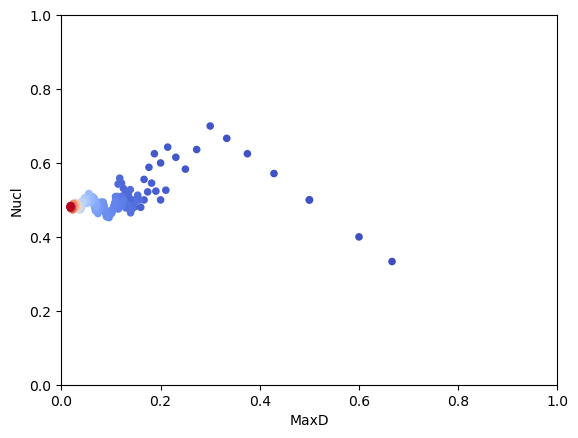

In [54]:
df_test1.plot.scatter(x='MaxD', y='Nucl', c=series_to_colors(df_test1['Rel_Size']*1.),
                     xlim=(0, 1), ylim=(0, 1));

##### Cross redirection

In [14]:
def next_rnd_xr(g):
    gn = Network(g)
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    nodes = list(gn._nodes)
    n = rd.choice(nodes)
    gn.calc_cores_branches()
    leaves = gn._leaves
    hubs = gn._hubs
    if n in leaves:
        if g.order() == 2:
            neighbors = [1 - n]
        else:
            neighbors = hubs.copy()
    else:
        neighbors = leaves.copy()
    attach = rd.choice(neighbors)
    gc.add_edge(attach, g.order())
    return gc

In [15]:
def loop_rnd_xr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    for k in tqdm(range(n)):
        gc = next_rnd_xr(gc)
    return gc

In [16]:
def tracked_loop_rnd_xr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    coord_list = []
    rel_size_list = []
    for k in tqdm(range(n)):
        gc = next_rnd_xr(gc)
        gcn = Network(gc)
        coord_list.append(gcn._coord)
        rel_size_list.append(Fraction(gcn._n, g.order() + n))
    df_coord = pd.DataFrame(coord_list, columns = ['MaxD', 'Nucl'])
    df_coord['Rel_Size'] = rel_size_list
    return [gc, df_coord]

In [63]:
%%time

test5 = loop_rnd_xr(init, 5000)

  0%|          | 0/5000 [00:00<?, ?it/s]

CPU times: user 1min 21s, sys: 689 ms, total: 1min 22s
Wall time: 1min 22s


In [64]:
%%time

test5, df_test5 = tracked_loop_rnd_xr(init, 5000)

  0%|          | 0/5000 [00:00<?, ?it/s]

CPU times: user 2min 6s, sys: 1.04 s, total: 2min 7s
Wall time: 2min 6s


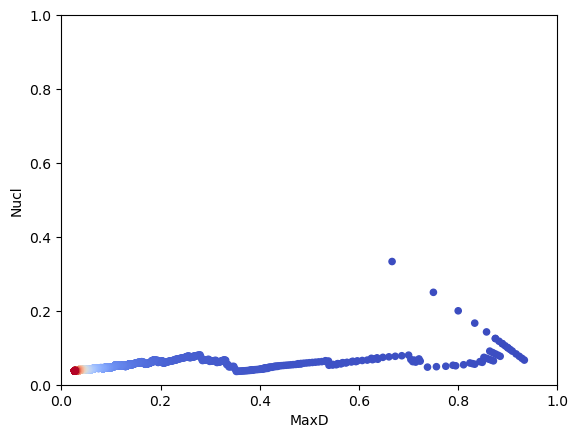

In [65]:
df_test5.plot.scatter(x='MaxD', y='Nucl', c=series_to_colors(df_test5['Rel_Size']*1.),
                     xlim=(0, 1), ylim=(0, 1));

##### Hub redirection

In [17]:
def next_rnd_hr(g):
    gn = Network(g)
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    nodes = list(gn._nodes)
    n = rd.choice(nodes)
    gn.calc_cores_branches()
    leaves = gn._leaves
    branches = gn._branches
    if n in leaves:
        if g.order() == 2:
            neighbors = [1 - n]
        else:
            neighbors = branches.copy()
    else:
        nodes_ex = nodes.copy()
        nodes_ex.remove(n)
        neighbors = nodes_ex.copy()
    attach = rd.choice(neighbors)
    gc.add_edge(attach, g.order())
    return gc

In [18]:
def loop_rnd_hr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    for k in tqdm(range(n)):
        gc = next_rnd_hr(gc)
    return gc

In [19]:
def tracked_loop_rnd_hr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    coord_list = []
    rel_size_list = []
    for k in tqdm(range(n)):
        gc = next_rnd_hr(gc)
        gcn = Network(gc)
        coord_list.append(gcn._coord)
        rel_size_list.append(Fraction(gcn._n, g.order() + n))
    df_coord = pd.DataFrame(coord_list, columns = ['MaxD', 'Nucl'])
    df_coord['Rel_Size'] = rel_size_list
    return [gc, df_coord]

In [60]:
%%time

test4 = loop_rnd_hr(init, 5000)

  0%|          | 0/5000 [00:00<?, ?it/s]

CPU times: user 1min 27s, sys: 611 ms, total: 1min 27s
Wall time: 1min 27s


In [61]:
%%time

test4, df_test4 = tracked_loop_rnd_hr(init, 5000)

  0%|          | 0/5000 [00:00<?, ?it/s]

CPU times: user 2min 9s, sys: 989 ms, total: 2min 10s
Wall time: 2min 10s


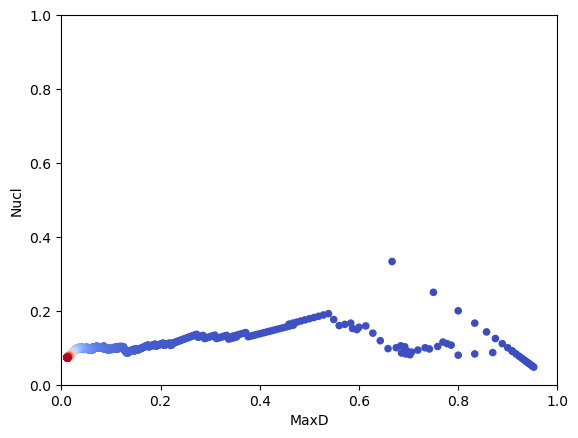

In [62]:
df_test4.plot.scatter(x='MaxD', y='Nucl', c=series_to_colors(df_test4['Rel_Size']*1.),
                     xlim=(0, 1), ylim=(0, 1));

##### Fuzzy redirection

In [20]:
def next_rnd_fr(g):
    gn = Network(g)
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    nodes = list(gn._nodes)
    n = rd.choice(nodes)
    gn.calc_cores_branches()
    leaves = gn._leaves
    branches = gn._branches
    cores = gn._cores
    if n in leaves:
        if g.order() == 2:
            neighbors = [1 - n]
        else:
            neighbors = branches.copy()
    elif n in cores:
        cores_ex = cores.copy()
        cores_ex.remove(n)
        neighbors = branches + cores_ex
    else:
        nodes_ex = nodes.copy()
        nodes_ex.remove(n)
        neighbors = nodes_ex.copy()
    attach = rd.choice(neighbors)
    gc.add_edge(attach, g.order())
    return gc

In [21]:
def loop_rnd_fr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    for k in tqdm(range(n)):
        gc = next_rnd_fr(gc)
    return gc

In [22]:
def tracked_loop_rnd_fr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    coord_list = []
    rel_size_list = []
    for k in tqdm(range(n)):
        gc = next_rnd_fr(gc)
        gcn = Network(gc)
        coord_list.append(gcn._coord)
        rel_size_list.append(Fraction(gcn._n, g.order() + n))
    df_coord = pd.DataFrame(coord_list, columns = ['MaxD', 'Nucl'])
    df_coord['Rel_Size'] = rel_size_list
    return [gc, df_coord]

In [58]:
%%time

test3 = loop_rnd_fr(init, 5000)

  0%|          | 0/5000 [00:00<?, ?it/s]

CPU times: user 1min 19s, sys: 528 ms, total: 1min 19s
Wall time: 1min 19s


In [29]:
%%time

test3, df_test3 = tracked_loop_rnd_fr(init, 5000)

  0%|          | 0/5000 [00:00<?, ?it/s]

CPU times: user 2min 7s, sys: 1.02 s, total: 2min 8s
Wall time: 2min 8s


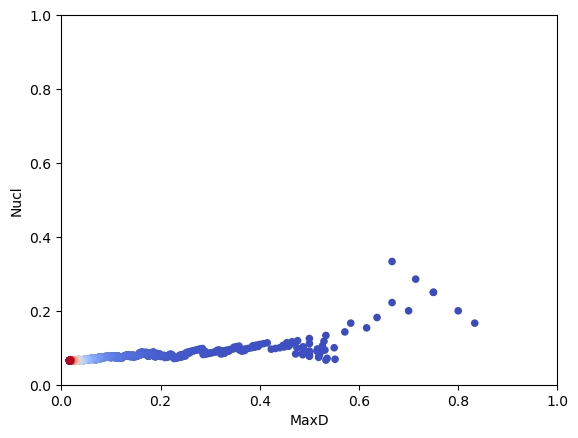

In [59]:
df_test3.plot.scatter(x='MaxD', y='Nucl', c=series_to_colors(df_test3['Rel_Size']*1.),
                     xlim=(0, 1), ylim=(0, 1));

##### Complete redirection

In [23]:
def next_rnd_cr(g):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    nodes = list(g.nodes)
    n = rd.choice(nodes)
    neighbors = list(g.neighbors(n))
    attach = rd.choice(neighbors)
    gc.add_edge(attach, g.order())
    return gc

In [24]:
def loop_rnd_cr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    for k in tqdm(range(n)):
        gc = next_rnd_cr(gc)
    return gc

In [25]:
def tracked_loop_rnd_cr(g, n):
    gc = nx.Graph()
    gc.add_nodes_from(g)
    gc.add_edges_from(g.edges)
    coord_list = []
    rel_size_list = []
    for k in tqdm(range(n)):
        gc = next_rnd_cr(gc)
        gcn = Network(gc)
        coord_list.append(gcn._coord)
        rel_size_list.append(Fraction(gcn._n, g.order() + n))
    df_coord = pd.DataFrame(coord_list, columns = ['MaxD', 'Nucl'])
    df_coord['Rel_Size'] = rel_size_list
    return [gc, df_coord]

In [26]:
%%time

test2 = loop_rnd_cr(init, 5000)

  0%|          | 0/5000 [00:00<?, ?it/s]

CPU times: user 20.8 s, sys: 265 ms, total: 21.1 s
Wall time: 21 s


In [56]:
%%time

test2, df_test2 = tracked_loop_rnd_cr(init, 5000)

  0%|          | 0/5000 [00:00<?, ?it/s]

CPU times: user 1min 2s, sys: 409 ms, total: 1min 3s
Wall time: 1min 3s


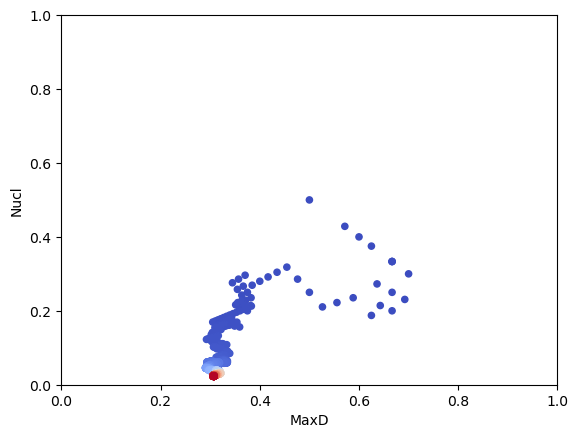

In [57]:
df_test2.plot.scatter(x='MaxD', y='Nucl', c=series_to_colors(df_test2['Rel_Size']*1.),
                     xlim=(0, 1), ylim=(0, 1));

## Examples - Run for large N

### Functions

In [26]:
def run_func_not(model, func, size, runs, start=init):
    data_runs = []
    start_size = start.order()
    for k in tqdm(range(runs)):
        runG = nx.Graph()
        runG.add_nodes_from(start)
        runG.add_edges_from(start.edges)
        for j in range(start_size + 1, size + 1):
            runG = func(runG)
        gok = Network(runG)
        gok.calc_cores_branches()
        gok.calc_mus()
        gok.calc_ros()
        data_runs = data_runs + [[model, k, gok._h, gok._hf * 1., gok._max_degree, gok._max_degree_f * 1.,
                                  gok._pd * 1., gok._dpd * 1., gok._ro * 1., gok._ph * 1., gok._dph * 1., gok._mu * 1.]]
    df_runs = pd.DataFrame(data_runs, columns=['Model', 'run', 'Nucl', 'NuclF', 'MaxD', 'MaxDF',
                                               'PD1', 'DPD', 'Ro', 'PH1', 'DPH', 'Mu'])
    return df_runs

In [133]:
def plot_beta_fit(df_data, model='XR', a=1, b=2, bin_width=0.01, bin_range=(0, 1)):
    ab = 'Beta(' + str(a) + ', ' + str(b) + ')'
    x = np.linspace(beta.ppf(0.001, a, b), beta.ppf(0.999, a, b), 1000)
    df_beta = pd.DataFrame((bin_width / 0.01) * beta.pdf(x, a, b), index=x, columns=[ab])
    fig = plt.figure()
    ax1 = fig.add_subplot(111)
    # ax2 = ax1.twinx()
    x_min = max(0, bin_range[0] + bin_width / 2)
    x_max = min(1, bin_range[1] - bin_width / 2)
    sns.lineplot(data=df_beta, ax=ax1, palette=['r'])
    sns.histplot(df_data, x='NuclF', stat='percent', binwidth=bin_width,
                 binrange=(x_min, x_max), ax=ax1)
    plt.title(model)
    plt.show()

### N=20

##### Complete redirection

In [177]:
%%time

CR20 = run_func_not('CR', next_rnd_cr, 20, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 4.7 s, sys: 34.1 ms, total: 4.73 s
Wall time: 4.72 s


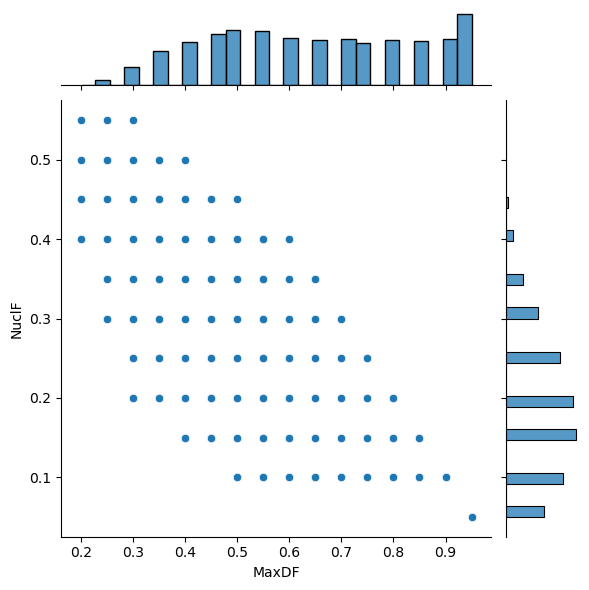

In [178]:
sns.jointplot(CR20, x='MaxDF', y='NuclF');

In [179]:
beta.fit(CR20['NuclF'], floc=0, fscale=1)

(3.136857561047342, 13.63088440919057, 0, 1)

In [192]:
beta.fit(CR20['NuclF'], f0=3, floc=0, fscale=1, method='MM')

(3, 13.004663021176826, 0, 1)

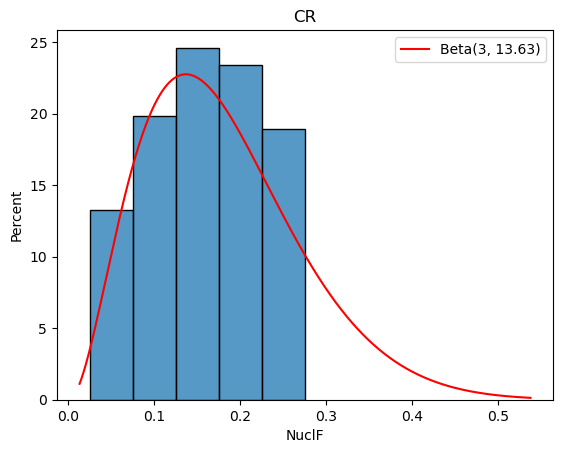

In [186]:
plot_beta_fit(CR20, model='CR', a=3, b=13.63, bin_width=0.05, bin_range=(0, 0.3))

### N=50

##### Complete redirection

In [181]:
%%time

CR50 = run_func_not('CR', next_rnd_cr, 50, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 17.9 s, sys: 110 ms, total: 18 s
Wall time: 18 s


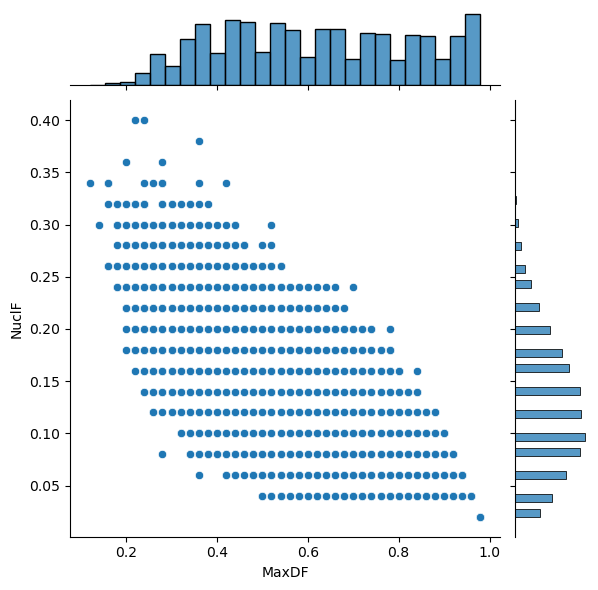

In [182]:
sns.jointplot(CR50, x='MaxDF', y='NuclF');

In [183]:
beta.fit(CR50['NuclF'], floc=0, fscale=1)

(3.0756102044789606, 21.108963211505486, 0, 1)

In [193]:
beta.fit(CR50['NuclF'], f0=3, floc=0, fscale=1, method='MM')

(3, 20.530916361196773, 0, 1)

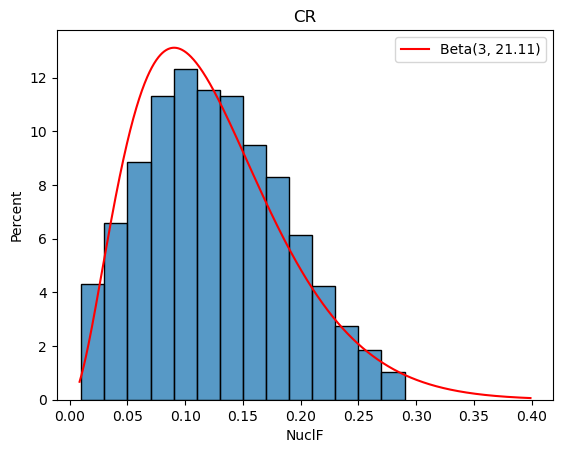

In [185]:
plot_beta_fit(CR50, model='CR', a=3, b=21.11, bin_width=0.02, bin_range=(0, 0.3))

### N=100

##### No redirection

In [27]:
%%time

NR100 = run_func_not('NR', next_rnd_nr, 100, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 1min 1s, sys: 344 ms, total: 1min 2s
Wall time: 1min 2s


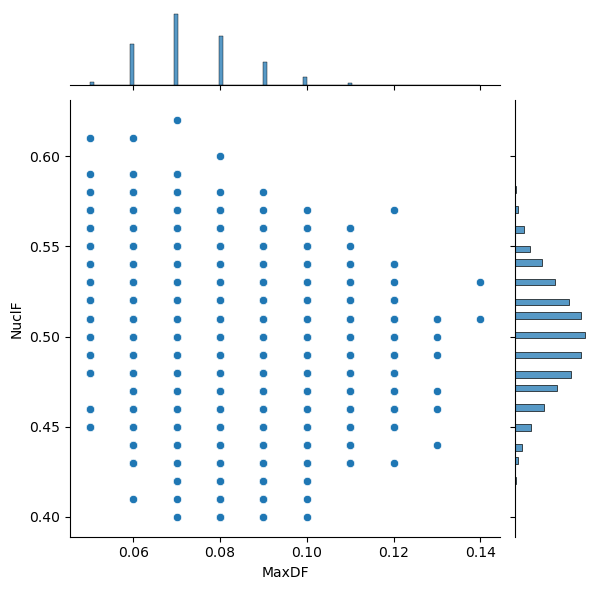

In [28]:
sns.jointplot(NR100, x='MaxDF', y='NuclF');

In [32]:
beta.fit(NR100['NuclF'], floc=0, fscale=1)

(150.8027519007419, 150.9718646265567, 0, 1)

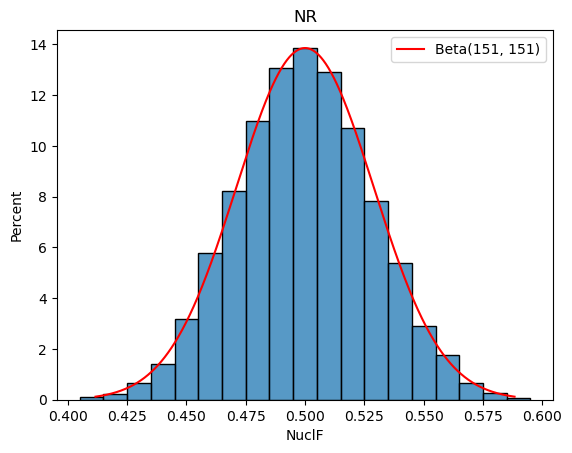

In [153]:
plot_beta_fit(NR100, model='NR', a=151, b=151, bin_width=0.01, bin_range=(0.4, 0.6))

##### Cross redirection

In [56]:
%%time

XR100 = run_func_not('XR', next_rnd_xr, 100, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 5min 26s, sys: 3.82 s, total: 5min 30s
Wall time: 5min 28s


In [19]:
%%time

XR_all_100 = run_func_not('XR', next_rnd_xr, 100, 10000, init)
XR_all_100['Start'] = '2/3'

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 5min 27s, sys: 2.96 s, total: 5min 30s
Wall time: 5min 29s


In [20]:
star = build_tree([(0, 1), (0, 2), (0, 3)])

In [21]:
snake = build_tree([(0, 1), (1, 2), (2, 3)])

In [22]:
%%time

XR_star_100 = run_func_not('XR', next_rnd_xr, 100, 10000, star)
XR_star_100['Start'] = 'Star'

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 5min 19s, sys: 2.91 s, total: 5min 22s
Wall time: 5min 21s


In [23]:
%%time

HR_snake_100 = run_func_not('XR', next_rnd_xr, 100, 10000, snake)
HR_snake_100['Start'] = 'Snake'

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 5min 33s, sys: 3.47 s, total: 5min 36s
Wall time: 5min 35s


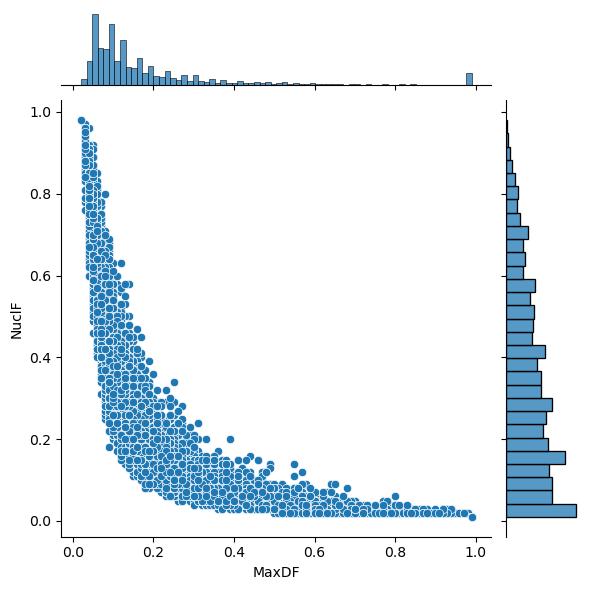

In [35]:
sns.jointplot(XR100, x='MaxDF', y='NuclF');

In [71]:
beta.fit(XR100['NuclF'], floc=0, fscale=1)

(1.086963487100366, 2.188685261941914, 0, 1)

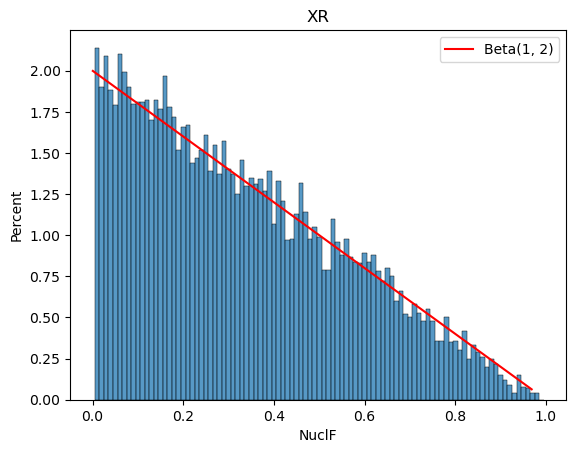

In [125]:
plot_beta_fit(XR100, model='XR', a=1, b=2, bin_width=0.01, bin_range=(0, 1))

In [38]:
XR_comp_100 = pd.concat([XR_all_100, XR_star_100, HR_snake_100], axis=0)

In [25]:
XR_comp_100.groupby('Start')[['MaxDF', 'PD1', 'DPD', 'NuclF', 'PH1', 'DPH']].mean()

,MaxDF,PD1,DPD,NuclF,PH1,DPH
Start,,,,,,
2/3,0.193582,0.170023,-0.000233,0.334563,0.122596,-0.002099
Snake,0.090582,0.078043,-0.000124,0.495149,0.138641,-0.003530
Star,0.244842,0.215923,-0.000286,0.250566,0.114981,-0.001342


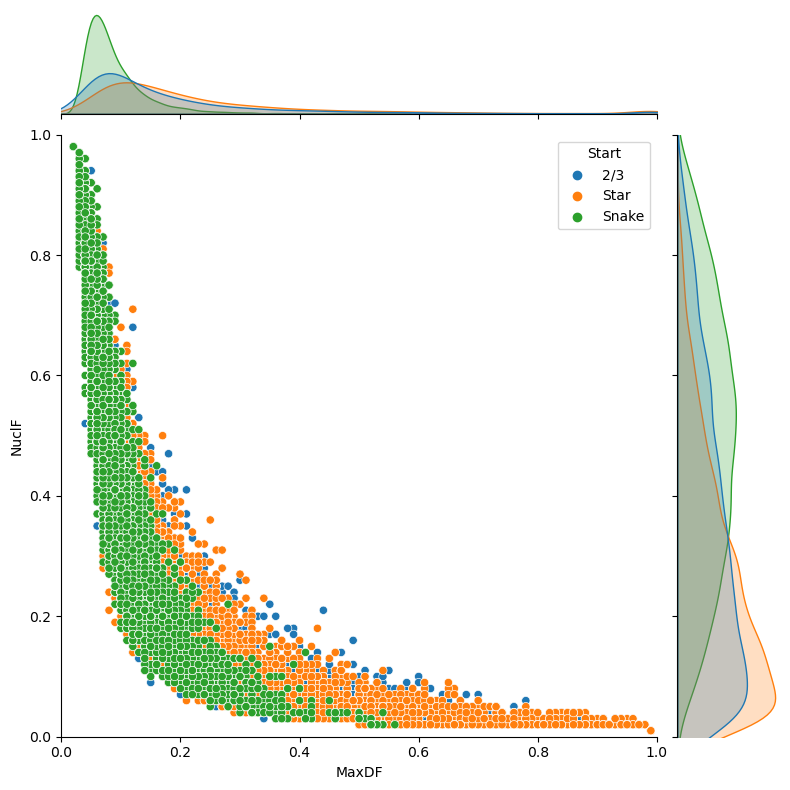

In [26]:
sns.jointplot(XR_comp_100, x='MaxDF', y='NuclF', hue='Start', height=8, xlim=(0, 1), ylim=(0, 1));

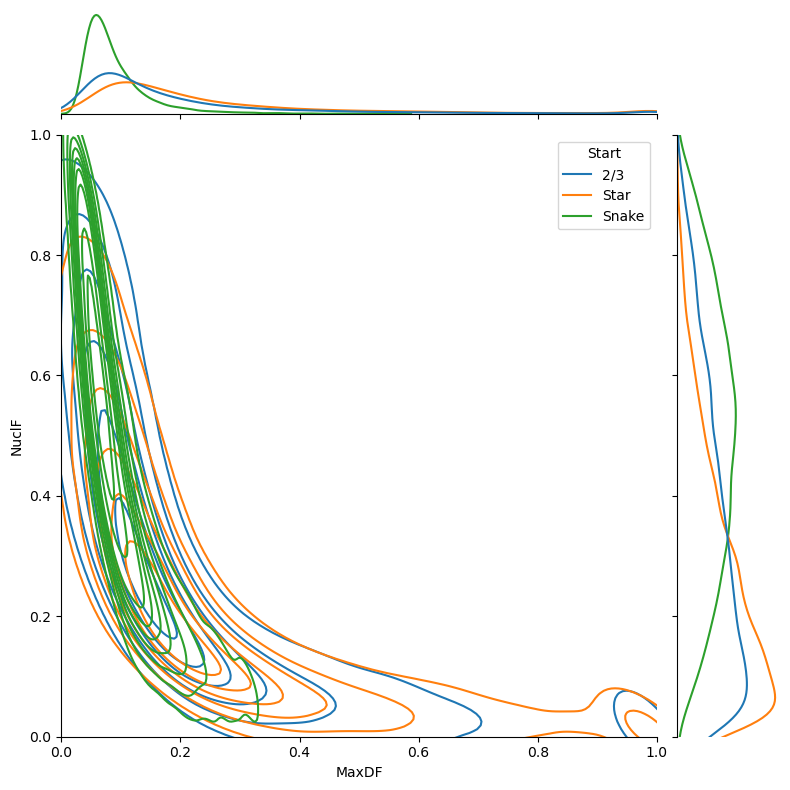

In [27]:
sns.jointplot(XR_comp_100, x='MaxDF', y='NuclF', hue='Start', height=8, xlim=(0, 1), ylim=(0, 1), kind='kde');

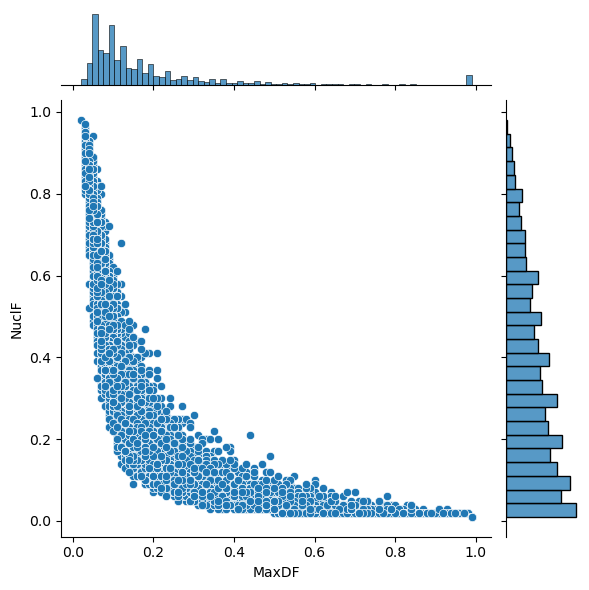

In [28]:
sns.jointplot(XR_all_100, x='MaxDF', y='NuclF');

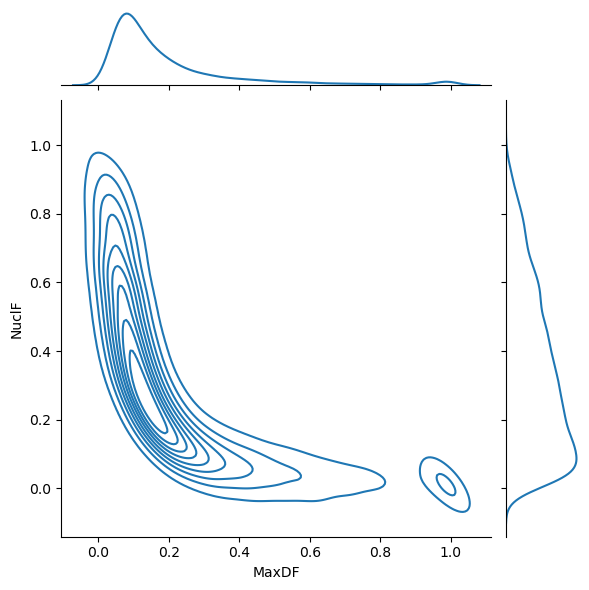

In [29]:
sns.jointplot(XR_all_100, x='MaxDF', y='NuclF', kind='kde');

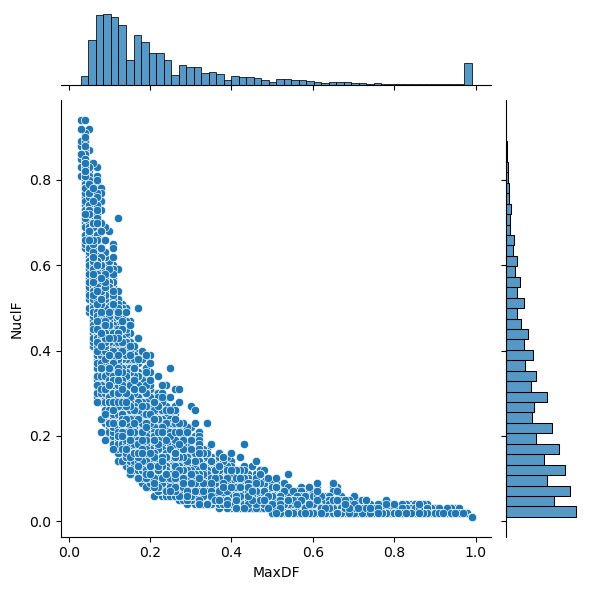

In [30]:
sns.jointplot(XR_star_100, x='MaxDF', y='NuclF');

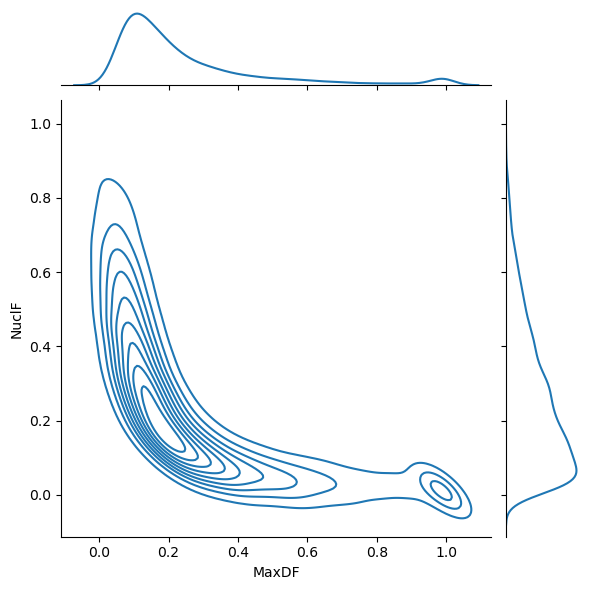

In [31]:
sns.jointplot(XR_star_100, x='MaxDF', y='NuclF', kind='kde');

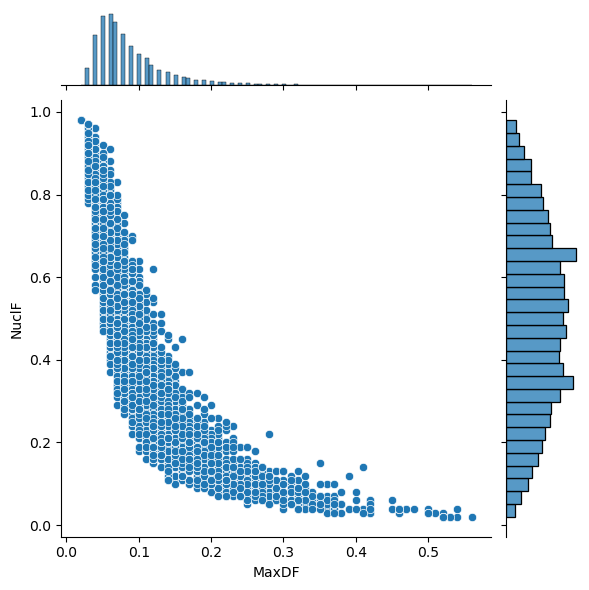

In [32]:
sns.jointplot(HR_snake_100, x='MaxDF', y='NuclF');

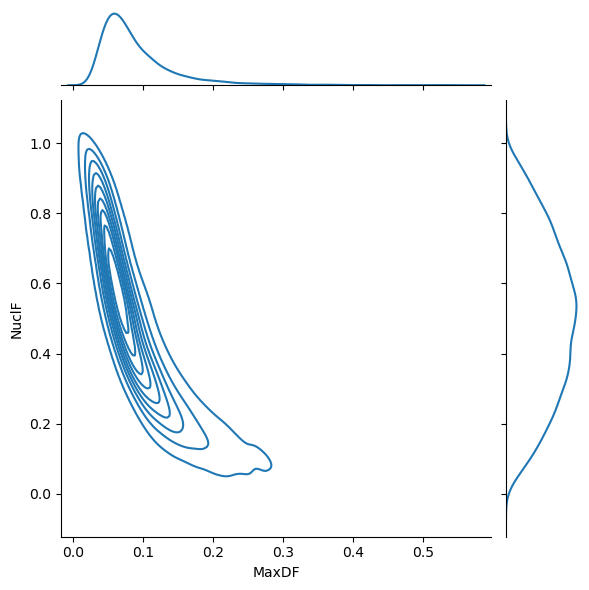

In [33]:
sns.jointplot(HR_snake_100, x='MaxDF', y='NuclF', kind='kde');

##### Hub redirection

In [85]:
%%time

HR100 = run_func_not('HR', next_rnd_hr, 100, 10000, init)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 5min 14s, sys: 2.75 s, total: 5min 17s
Wall time: 5min 15s


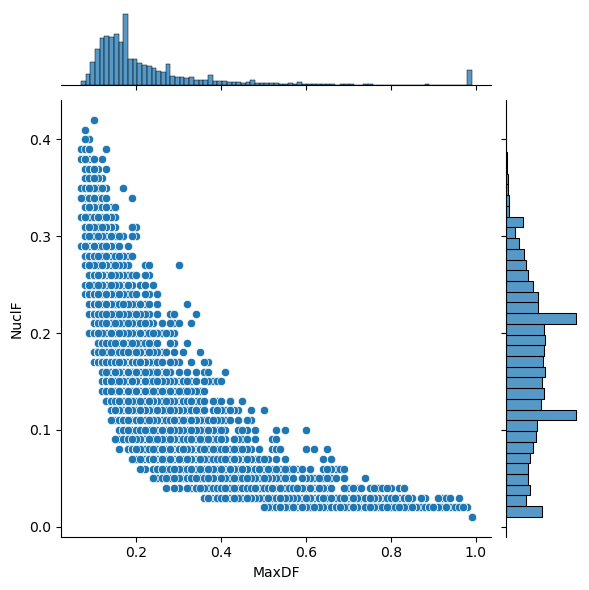

In [86]:
sns.jointplot(HR100, x='MaxDF', y='NuclF');

In [87]:
beta.fit(HR100['NuclF'], floc=0, fscale=1)

(2.4721950289230863, 13.051288012459493, 0, 1)

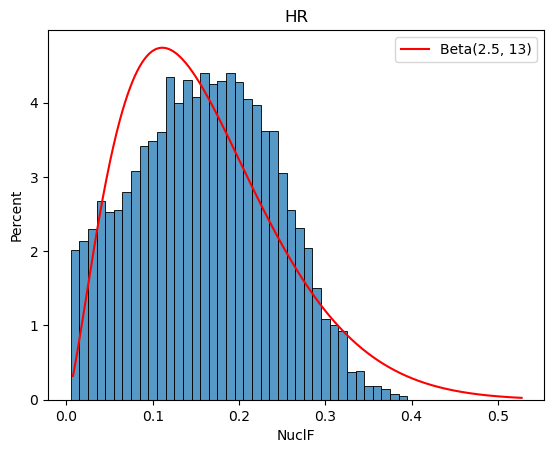

In [126]:
plot_beta_fit(HR100, model='HR', a=2.5, b=13, bin_width=0.01, bin_range=(0, 0.4))

##### Fuzzy redirection

In [91]:
%%time

FR100 = run_func_not('FR', next_rnd_fr, 100, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 5min 10s, sys: 2.56 s, total: 5min 13s
Wall time: 5min 11s


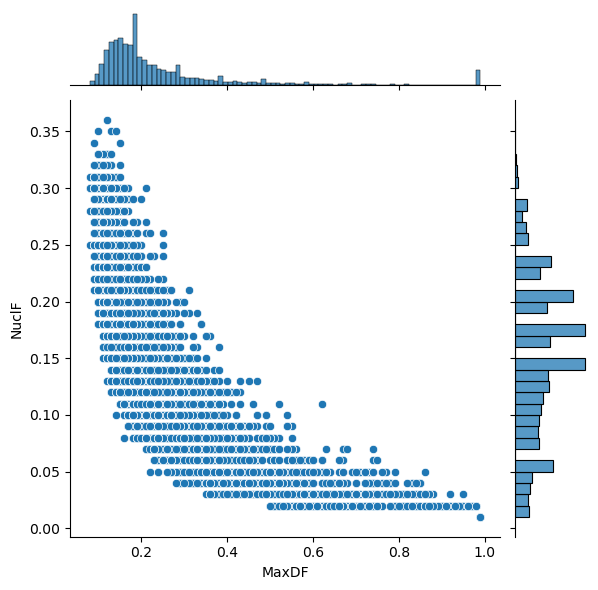

In [92]:
sns.jointplot(FR100, x='MaxDF', y='NuclF');

In [93]:
beta.fit(FR100['NuclF'], floc=0, fscale=1)

(2.7450946829602465, 16.240624780527202, 0, 1)

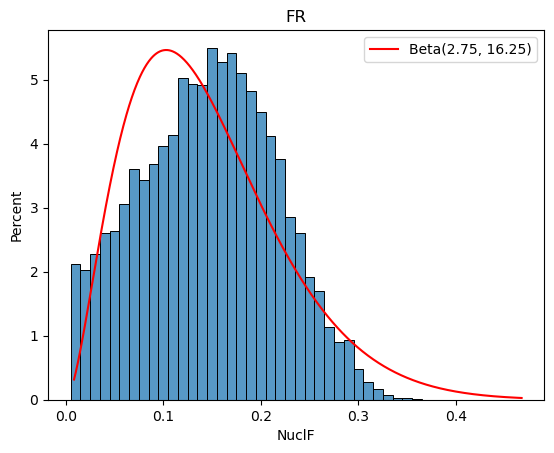

In [127]:
plot_beta_fit(FR100, model='FR', a=2.75, b=16.25, bin_width=0.01, bin_range=(0, 0.4))

##### Complete redirection

In [95]:
%%time

CR100 = run_func_not('CR', next_rnd_cr, 100, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 1min, sys: 275 ms, total: 1min
Wall time: 1min


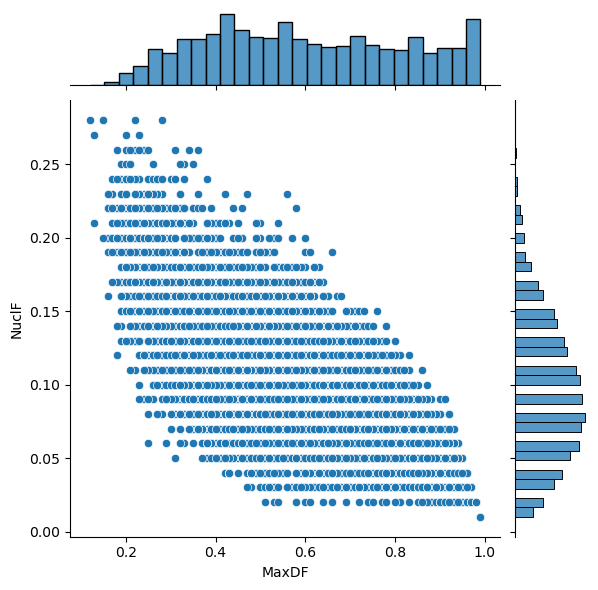

In [96]:
sns.jointplot(CR100, x='MaxDF', y='NuclF');

In [97]:
beta.fit(CR100['NuclF'], floc=0, fscale=1)

(3.005964192577695, 28.32839444588705, 0, 1)

In [194]:
beta.fit(CR100['NuclF'], f0=3, floc=0, fscale=1, method='MM')

(3, 28.199993123971705, 0, 1)

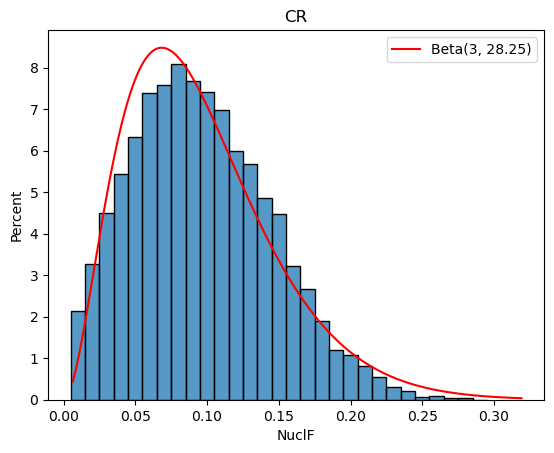

In [128]:
plot_beta_fit(CR100, model='CR', a=3, b=28.25, bin_width=0.01, bin_range=(0, 0.3))

#### Compare

In [42]:
df100 = pd.concat([NR100, XR100, HR100, FR100, CR100], axis=0)

In [43]:
df100.groupby('Model')[['MaxDF', 'PD1', 'DPD', 'NuclF', 'PH1', 'DPH']].mean()

,MaxDF,PD1,DPD,NuclF,PH1,DPH
Model,,,,,,
CR,0.593147,0.574864,-0.000181,0.096348,0.055491,-0.000405
FR,0.251209,0.231129,-0.000199,0.144140,0.096148,-0.000475
HR,0.243884,0.222749,-0.000209,0.159495,0.101791,-0.000571
NR,0.074511,0.054326,-0.000200,0.499735,0.170432,-0.003260
XR,0.195855,0.172993,-0.000226,0.334074,0.122876,-0.002091


In [44]:
(100.)**(0.566-1)

0.13551894123510358

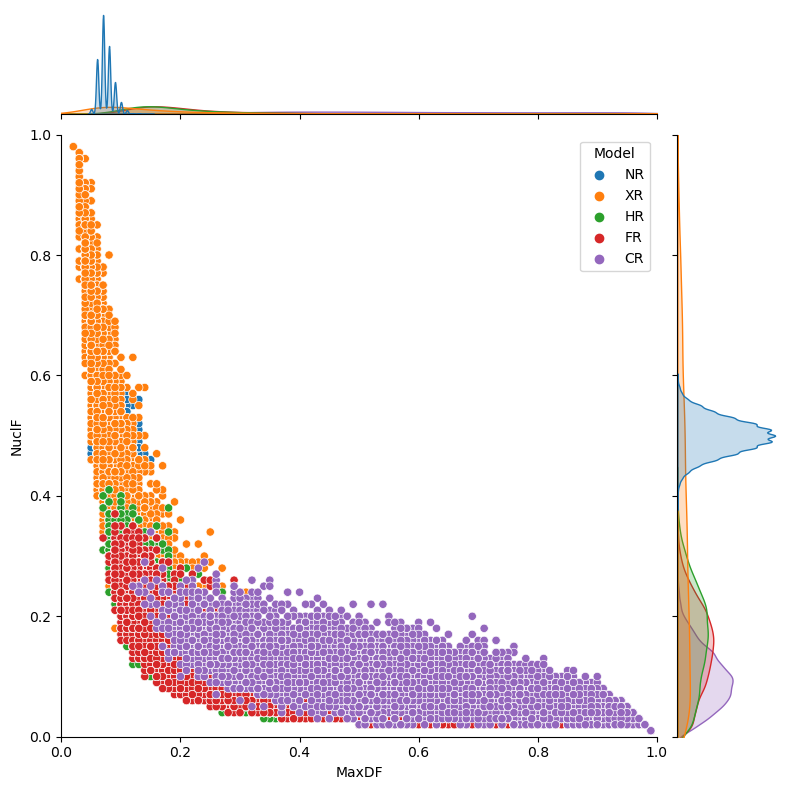

In [45]:
sns.jointplot(df100, x='MaxDF', y='NuclF', hue='Model', height=8, xlim=(0, 1), ylim=(0, 1));

In [46]:
subdf100 = pd.concat([XR100, FR100, CR100], axis=0)

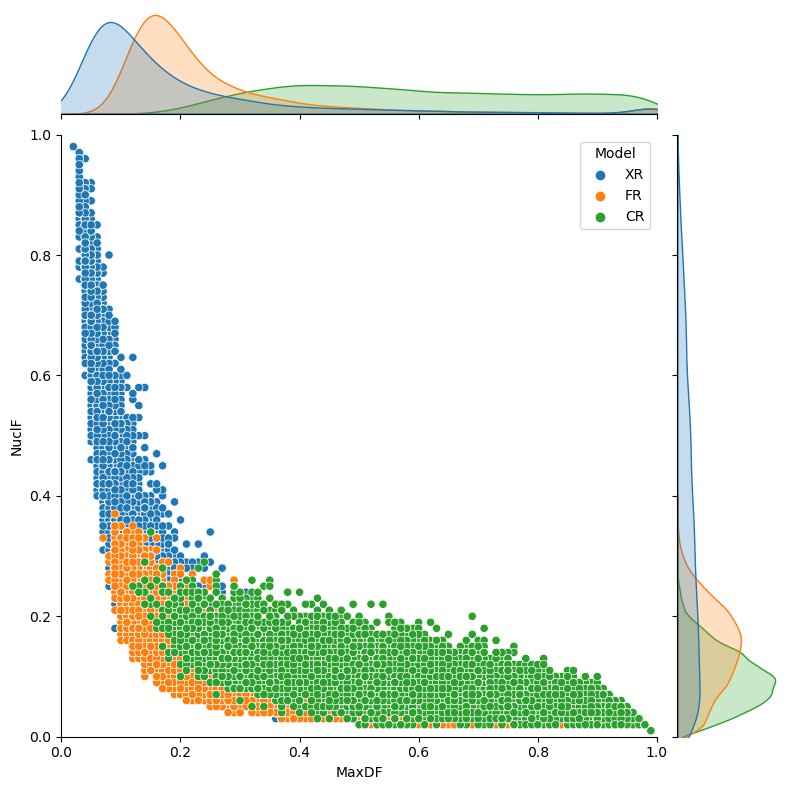

In [47]:
sns.jointplot(subdf100, x='MaxDF', y='NuclF', hue='Model', height=8, xlim=(0, 1), ylim=(0, 1));

### N=200

##### Complete redirection

In [187]:
%%time

CR200 = run_func_not('CR', next_rnd_cr, 200, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 3min 51s, sys: 1.2 s, total: 3min 53s
Wall time: 3min 52s


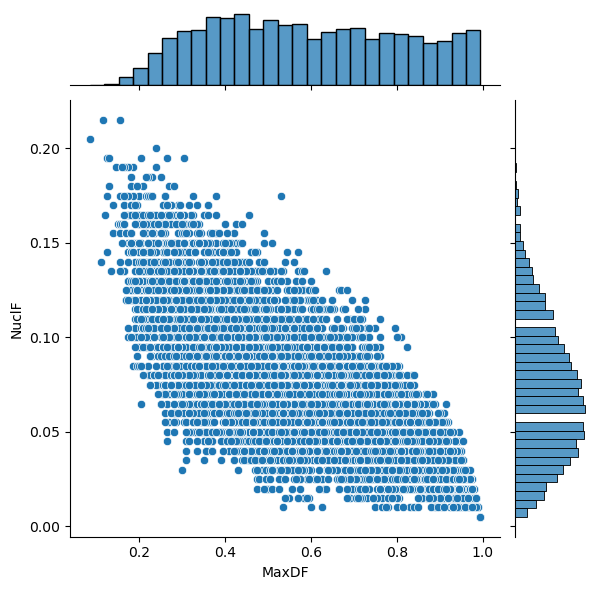

In [188]:
sns.jointplot(CR200, x='MaxDF', y='NuclF');

In [189]:
beta.fit(CR200['NuclF'], floc=0, fscale=1)

(3.0938726684991527, 40.37668196989808, 0, 1)

In [190]:
beta.fit(CR200['NuclF'], f0=3, floc=0, fscale=1)

(3, 39.1666403876199, 0, 1)

In [191]:
beta.fit(CR200['NuclF'], f0=3, floc=0, fscale=1, method='MM')

(3, 39.076331437658226, 0, 1)

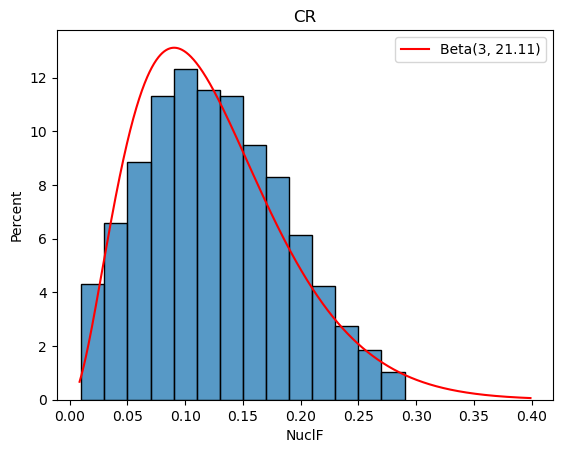

In [185]:
plot_beta_fit(CR200, model='CR', a=3, b=21.11, bin_width=0.01, bin_range=(0, 0.3))

### N=400

##### No redirection

In [161]:
%%time

NR400 = run_func_not('NR', next_rnd_nr, 400, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 15min 57s, sys: 4.02 s, total: 16min 1s
Wall time: 16min


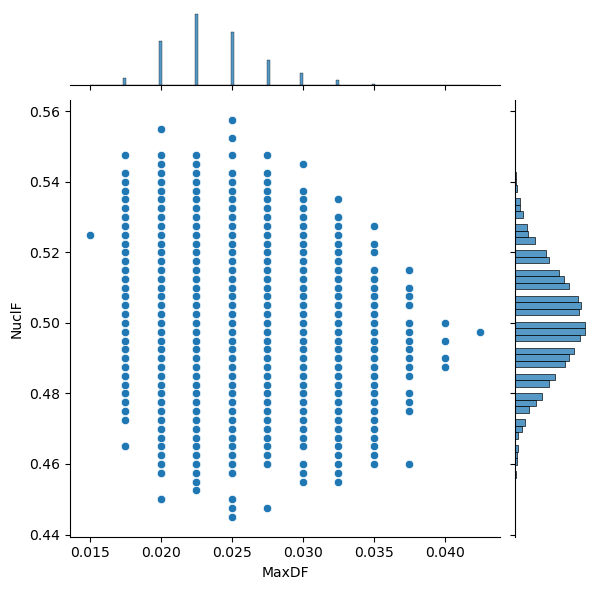

In [162]:
sns.jointplot(NR400, x='MaxDF', y='NuclF');

In [163]:
beta.fit(NR400['NuclF'], floc=0, fscale=1)

(601.8157355290643, 601.1497124895769, 0, 1)

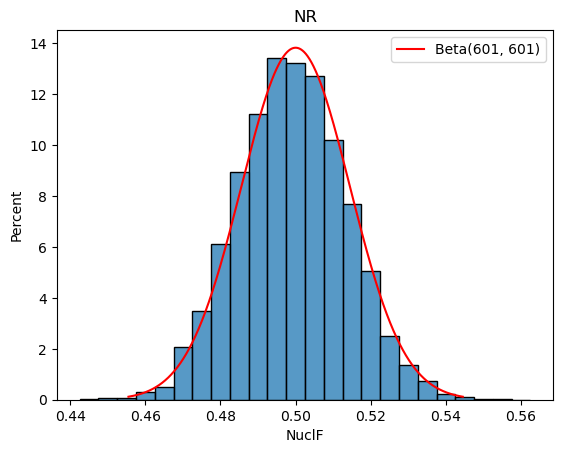

In [165]:
plot_beta_fit(NR400, model='NR', a=601, b=601, bin_width=0.005, bin_range=(0.44, 0.56))

##### Complete redirection

In [154]:
%%time

CR400 = run_func_not('CR', next_rnd_cr, 400, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 15min 41s, sys: 3.86 s, total: 15min 45s
Wall time: 15min 44s


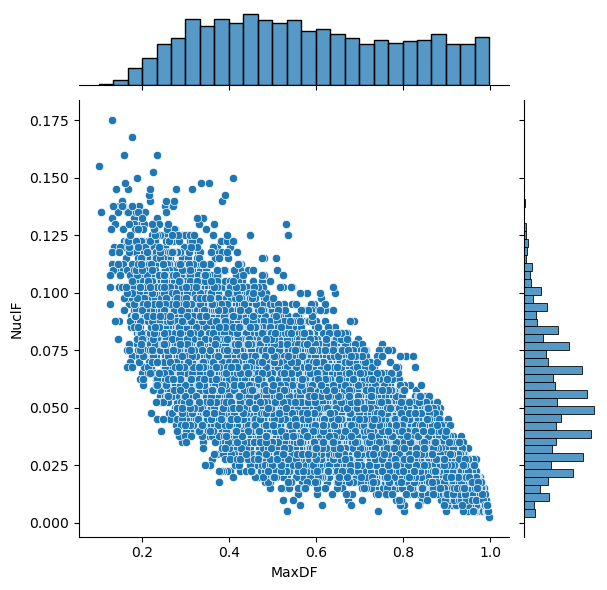

In [155]:
sns.jointplot(CR400, x='MaxDF', y='NuclF');

In [156]:
beta.fit(CR400['NuclF'], floc=0, fscale=1)

(3.1191499470564383, 55.4103439309672, 0, 1)

In [195]:
beta.fit(CR400['NuclF'], f0=3, floc=0, fscale=1, method='MM')

/opt/miniconda3/envs/pyenv/lib/python3.10/site-packages/scipy/stats/_continuous_distns.py:684: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)


(3, 53.21715835229723, 0, 1)

In [196]:
beta.fit(CR400['NuclF'], floc=0, fscale=1, method='MM')

(3.6804627528545253, 65.28791171249304, 0, 1)

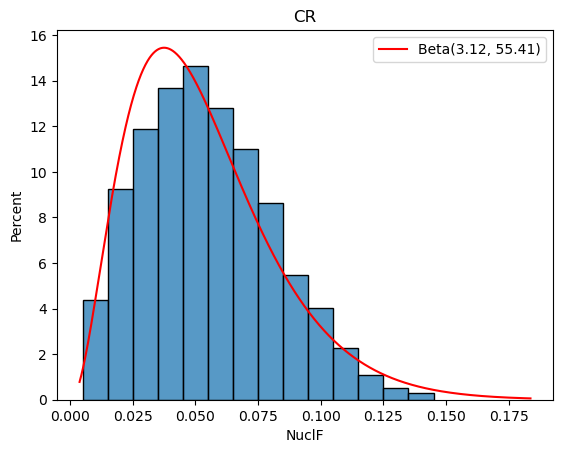

In [164]:
plot_beta_fit(CR400, model='CR', a=3.12, b=55.41, bin_width=0.01, bin_range=(0, 0.15))

### N=1000

##### No redirection

In [99]:
%%time

NR1000 = run_func_not('NR', next_rnd_nr, 1000, 1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 11min 29s, sys: 3.66 s, total: 11min 33s
Wall time: 11min 33s


In [170]:
%%time

NR1000_2 = run_func_not('NR', next_rnd_nr, 1000, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 1h 56min 48s, sys: 39.3 s, total: 1h 57min 27s
Wall time: 1h 57min 25s


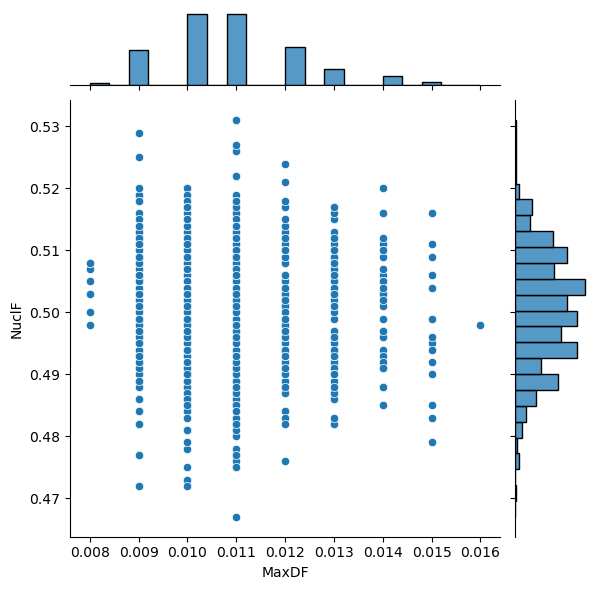

In [100]:
sns.jointplot(NR1000, x='MaxDF', y='NuclF');

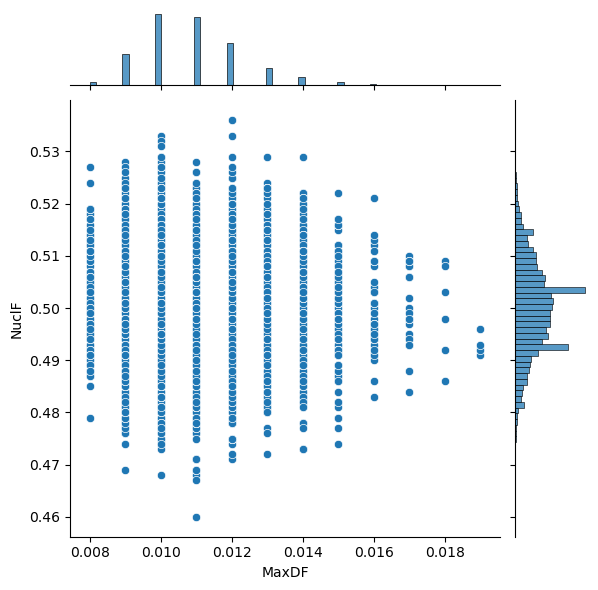

In [171]:
sns.jointplot(NR1000_2, x='MaxDF', y='NuclF');

In [129]:
beta.fit(NR1000['NuclF'], floc=0, fscale=1)

(1437.8860380063104, 1436.6851495877163, 0, 1)

In [172]:
beta.fit(NR1000_2['NuclF'], floc=0, fscale=1)

(1545.944933017031, 1545.6660662737422, 0, 1)

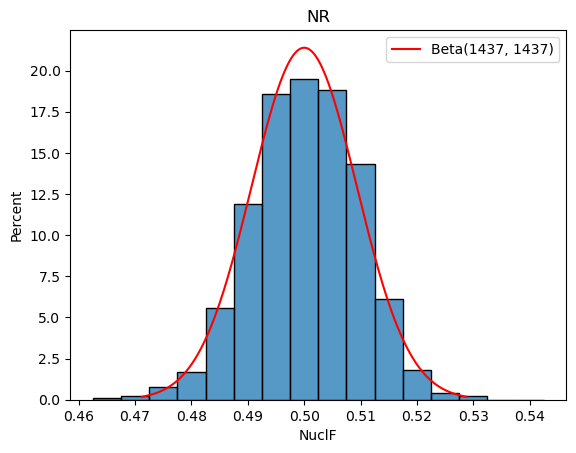

In [137]:
plot_beta_fit(NR1000, model='NR', a=1437, b=1437, bin_width=0.005, bin_range=(0.46, 0.54))

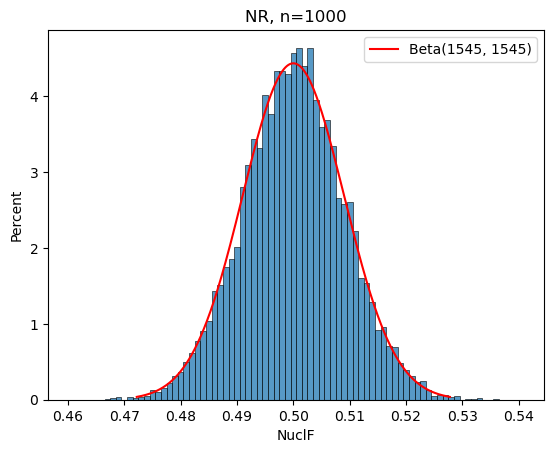

In [207]:
plot_beta_fit(NR1000_2, model='NR, n=1000', a=1545, b=1545, bin_width=0.001, bin_range=(0.46, 0.54))

##### Cross redirection

In [101]:
%%time

XR1000 = run_func_not('XR', next_rnd_xr, 1000, 1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 55min 30s, sys: 18.7 s, total: 55min 48s
Wall time: 55min 46s


In [34]:
%%time

XR_all_1000 = run_func_not('XR', next_rnd_xr, 1000, 1000, init)
XR_all_1000['Start'] = '2/3'

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 55min 7s, sys: 16.9 s, total: 55min 24s
Wall time: 55min 22s


In [39]:
%%time

XR_star_1000 = run_func_not('XR', next_rnd_xr, 1000, 1000, star)
XR_star_1000['Start'] = 'Star'

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 54min 35s, sys: 14.8 s, total: 54min 50s
Wall time: 54min 48s


In [40]:
%%time

HR_snake_1000 = run_func_not('XR', next_rnd_xr, 1000, 1000, snake)
HR_snake_1000['Start'] = 'Snake'

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 56min 57s, sys: 20 s, total: 57min 17s
Wall time: 57min 18s


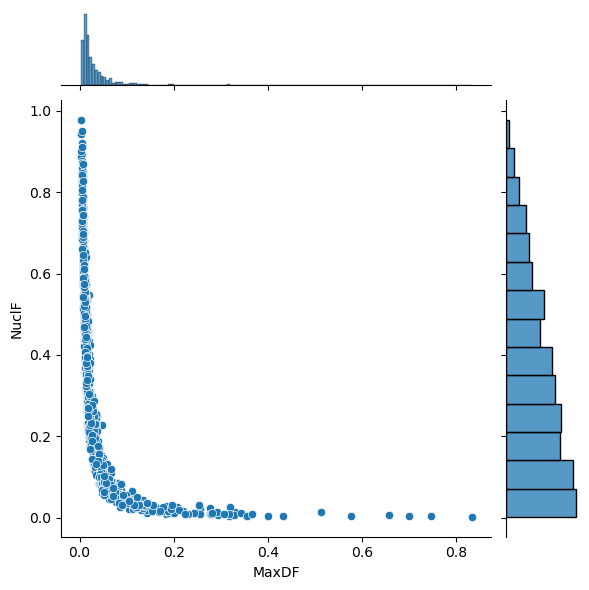

In [102]:
sns.jointplot(XR1000, x='MaxDF', y='NuclF');

In [138]:
beta.fit(XR1000['NuclF'], floc=0, fscale=1)

(1.0024447798240503, 2.054638455393534, 0, 1)

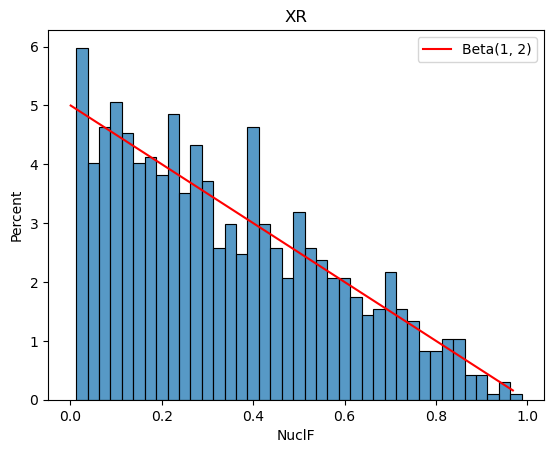

In [141]:
plot_beta_fit(XR1000, model='XR', a=1, b=2, bin_width=0.025, bin_range=(0, 1))

In [41]:
XR_comp_1000 = pd.concat([XR_all_1000, XR_star_1000, HR_snake_1000], axis=0)

In [42]:
XR_comp_1000.groupby('Start')[['MaxDF', 'PD1', 'DPD', 'NuclF', 'PH1', 'DPH']].mean()

,MaxDF,PD1,DPD,NuclF,PH1,DPH
Start,,,,,,
2/3,0.045918,0.039880,-0.000006,0.333858,0.119367,-0.000214
Snake,0.014710,0.010928,-0.000004,0.502233,0.136248,-0.000366
Star,0.055173,0.047585,-0.000008,0.254037,0.114288,-0.000140


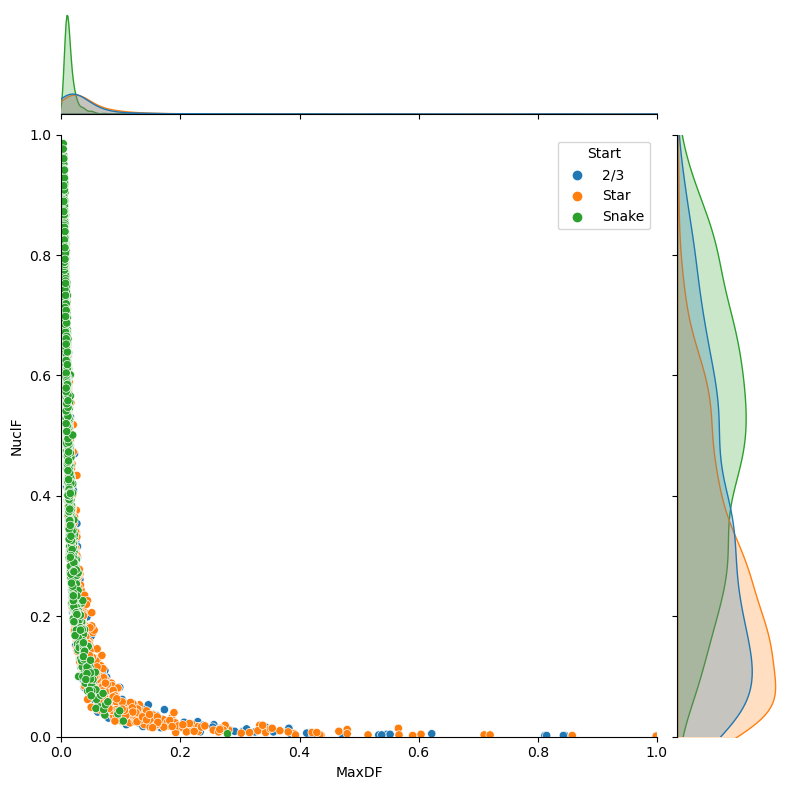

In [43]:
sns.jointplot(XR_comp_1000, x='MaxDF', y='NuclF', hue='Start', height=8, xlim=(0, 1), ylim=(0, 1));

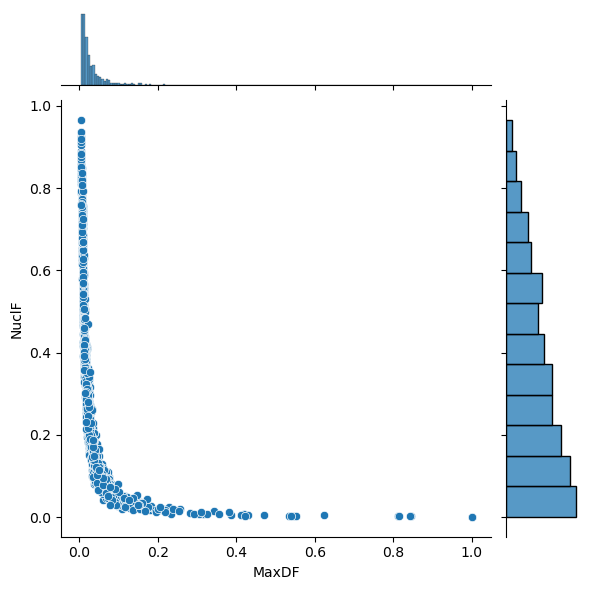

In [44]:
sns.jointplot(XR_all_1000, x='MaxDF', y='NuclF');

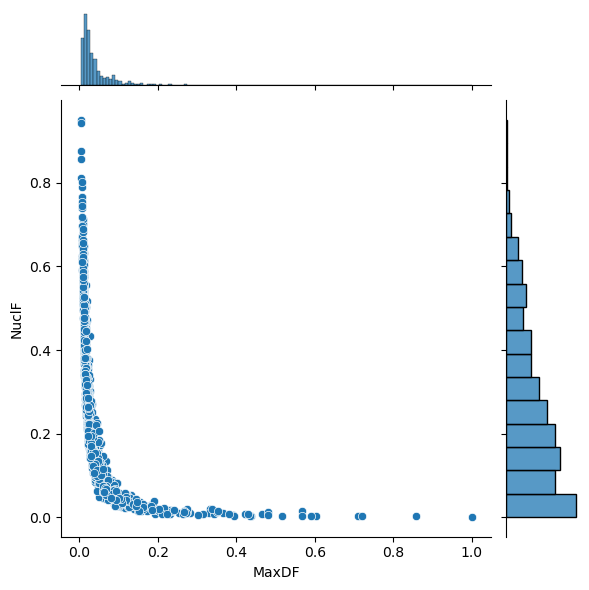

In [45]:
sns.jointplot(XR_star_1000, x='MaxDF', y='NuclF');

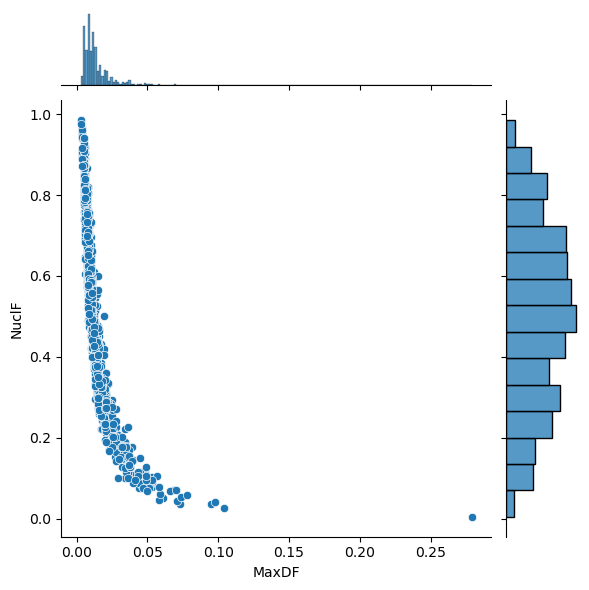

In [46]:
sns.jointplot(HR_snake_1000, x='MaxDF', y='NuclF');

##### Hub redirection

In [103]:
%%time

HR1000 = run_func_not('HR', next_rnd_hr, 1000, 1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 53min 4s, sys: 19.5 s, total: 53min 24s
Wall time: 53min 20s


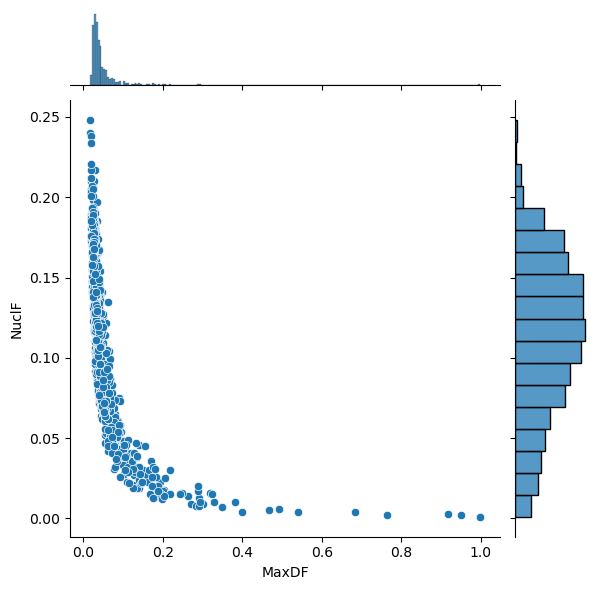

In [104]:
sns.jointplot(HR1000, x='MaxDF', y='NuclF');

In [142]:
beta.fit(HR1000['NuclF'], floc=0, fscale=1)

(3.0562205525890653, 24.29257880143857, 0, 1)

In [218]:
beta.fit(HR1000['NuclF'], f0=3, floc=0, fscale=1, method='MM')

(3, 23.668068718772403, 0, 1)

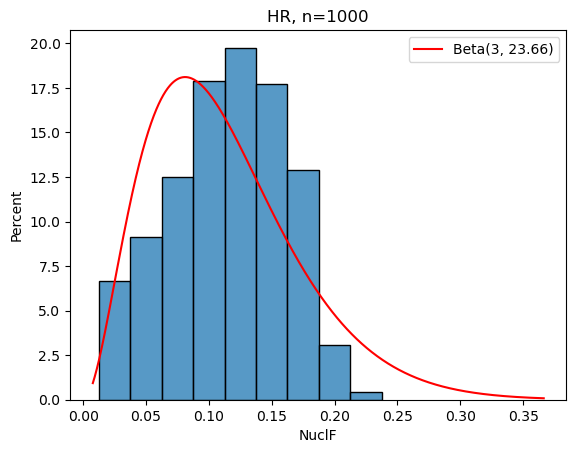

In [223]:
plot_beta_fit(HR1000, model='HR, n=1000', a=3, b=23.66, bin_width=0.025, bin_range=(0, 0.25))

##### Fuzzy redirection

In [105]:
%%time

FR1000 = run_func_not('FR', next_rnd_fr, 1000, 1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 53min 30s, sys: 26.9 s, total: 53min 57s
Wall time: 54min 4s


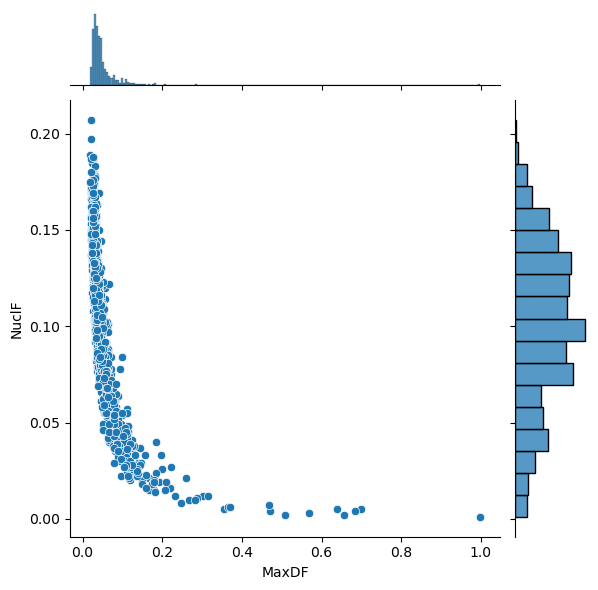

In [106]:
sns.jointplot(FR1000, x='MaxDF', y='NuclF');

In [144]:
beta.fit(FR1000['NuclF'], floc=0, fscale=1)

(3.372968862134887, 30.778997440196378, 0, 1)

In [220]:
beta.fit(FR1000['NuclF'], f0=3, floc=0, fscale=1, method='MM')

(3, 27.22119673209637, 0, 1)

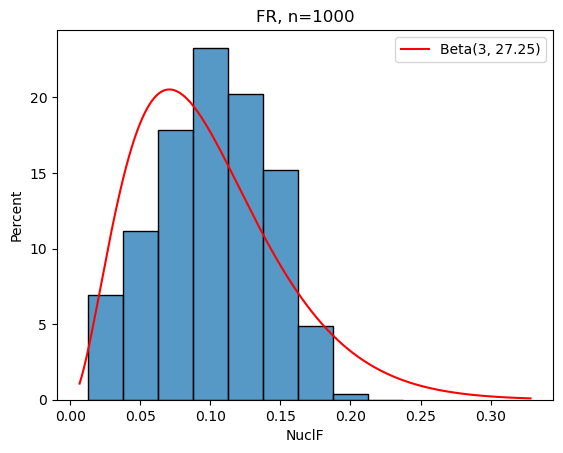

In [224]:
plot_beta_fit(FR1000, model='FR, n=1000', a=3, b=27.25, bin_width=0.025, bin_range=(0, 0.25))

##### Complete redirection

In [107]:
%%time

CR1000 = run_func_not('CR', next_rnd_cr, 1000, 1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 11min 13s, sys: 4.25 s, total: 11min 17s
Wall time: 11min 17s


In [166]:
%%time

CR1000_2 = run_func_not('CR', next_rnd_cr, 1000, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 1h 54min 38s, sys: 41.3 s, total: 1h 55min 20s
Wall time: 1h 55min 17s


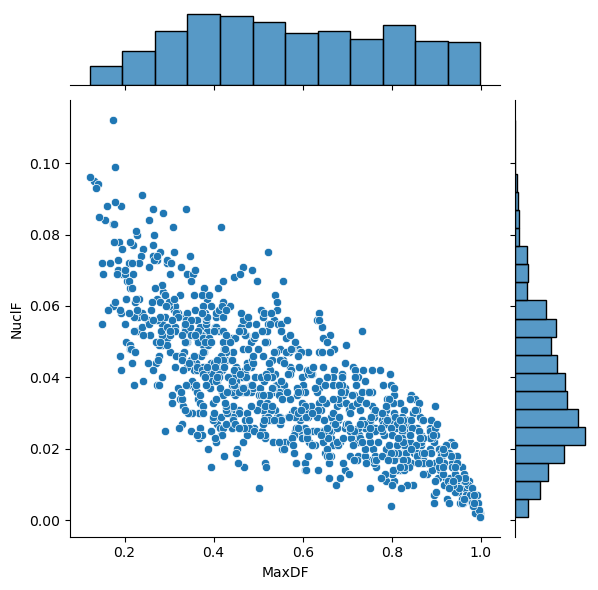

In [108]:
sns.jointplot(CR1000, x='MaxDF', y='NuclF');

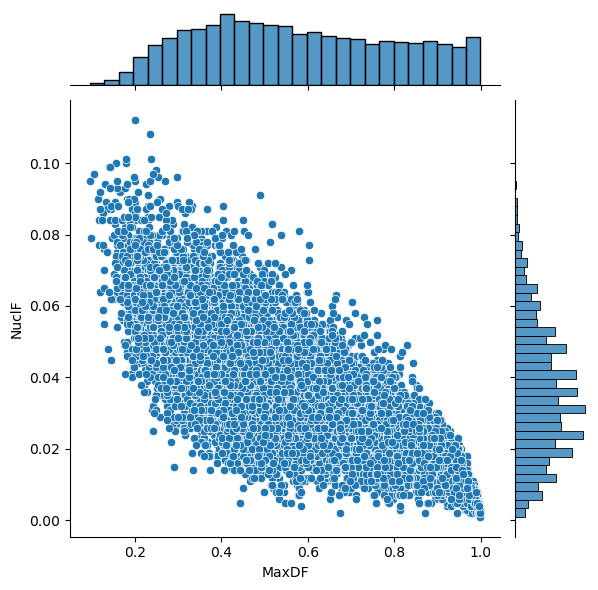

In [167]:
sns.jointplot(CR1000_2, x='MaxDF', y='NuclF');

In [146]:
beta.fit(CR1000['NuclF'], floc=0, fscale=1)

(3.2135685620410106, 84.7479636009706, 0, 1)

In [168]:
beta.fit(CR1000_2['NuclF'], floc=0, fscale=1)

(3.047783060555445, 82.29195388234307, 0, 1)

In [197]:
beta.fit(CR1000_2['NuclF'], f0=3, floc=0, fscale=1, method='MM')

(3, 80.91396328481952, 0, 1)

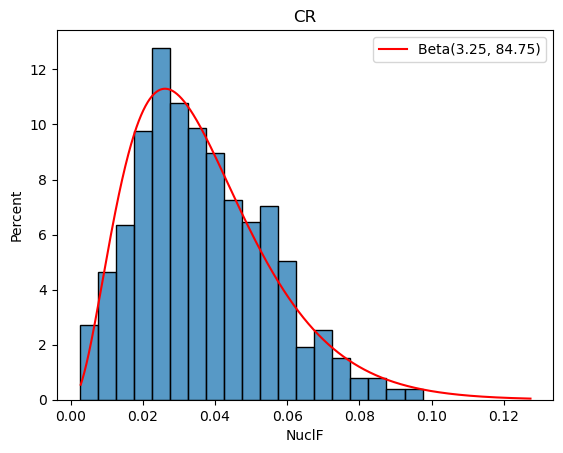

In [152]:
plot_beta_fit(CR1000, model='CR', a=3.25, b=84.75, bin_width=0.005, bin_range=(0, 0.10))

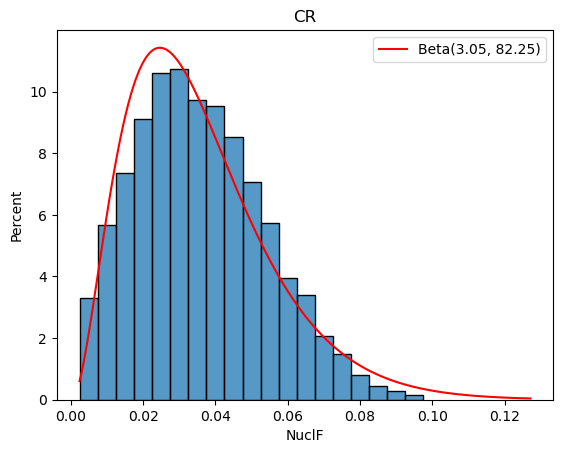

In [169]:
plot_beta_fit(CR1000_2, model='CR', a=3.05, b=82.25, bin_width=0.005, bin_range=(0, 0.10))

#### Compare

In [133]:
df1000 = pd.concat([NR1000, XR1000, HR1000, FR1000, CR1000], axis=0)

In [156]:
df1000.groupby('Model')[['MaxDF', 'PD1', 'DPD', 'NuclF', 'PH1', 'DPH']].mean()

,MaxDF,PD1,DPD,NuclF,PH1,DPH
Model,,,,,,
CR,0.564095,0.560049,0.000522,0.037355,0.021220,-0.000016
FR,0.057984,0.052455,-0.000047,0.099036,0.074373,-0.000025
HR,0.057169,0.051212,-0.000061,0.112770,0.081663,-0.000031
NR,0.010915,0.006714,-0.000492,0.499584,0.169919,-0.000329
XR,0.048487,0.042050,-0.000281,0.323517,0.119316,-0.000204


In [29]:
(1000.)**(0.566-1)

0.0498884487460012

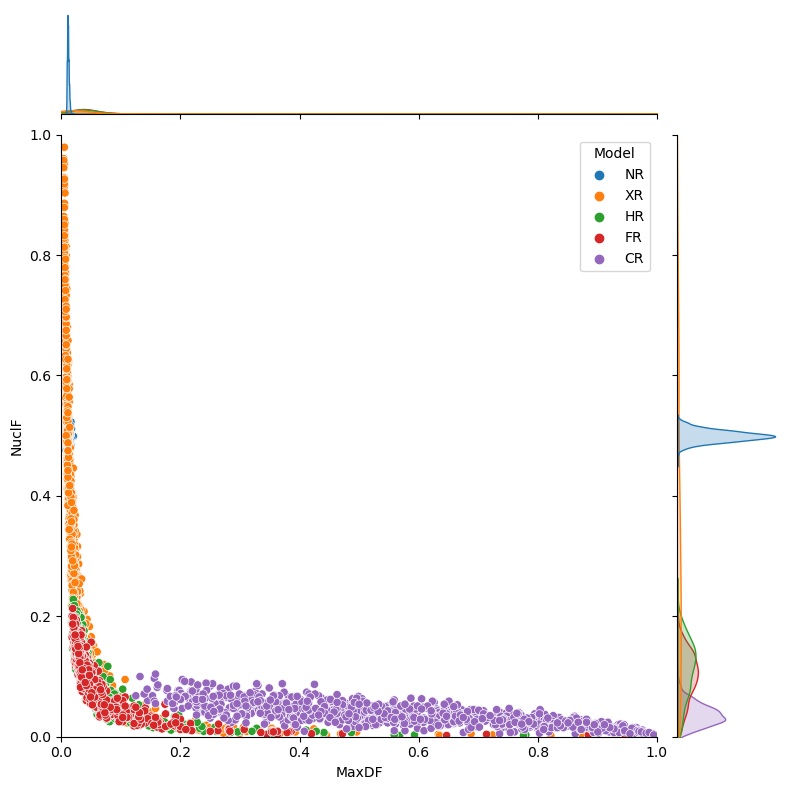

In [150]:
sns.jointplot(df1000, x='MaxDF', y='NuclF', hue='Model', height=8, xlim=(0, 1), ylim=(0, 1));

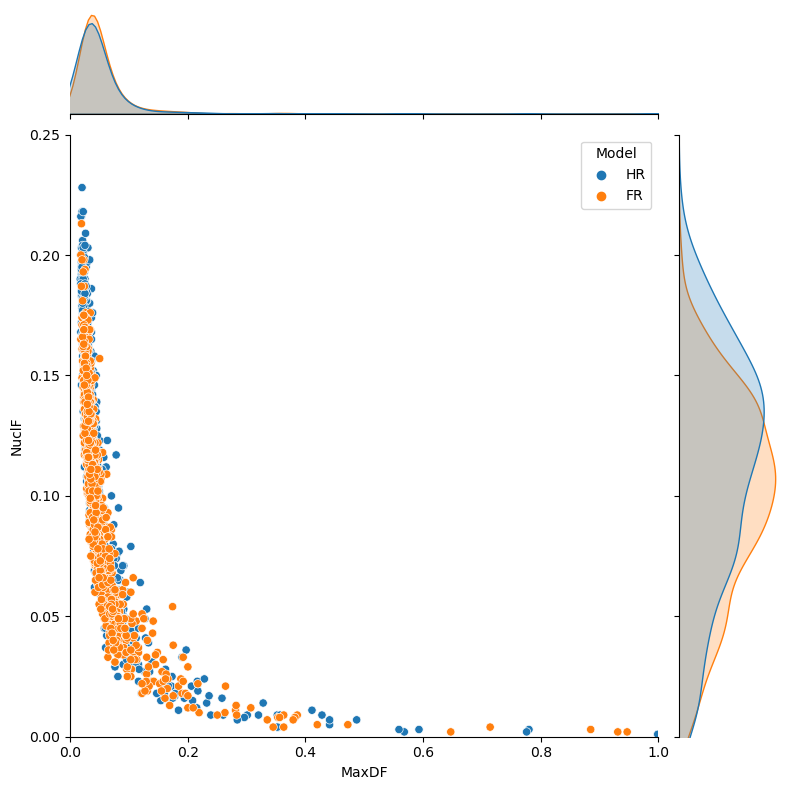

In [163]:
subdf1000 = pd.concat([HR1000, FR1000], axis=0)
sns.jointplot(subdf1000, x='MaxDF', y='NuclF', hue='Model', height=8, xlim=(0, 1), ylim=(0, 0.25));

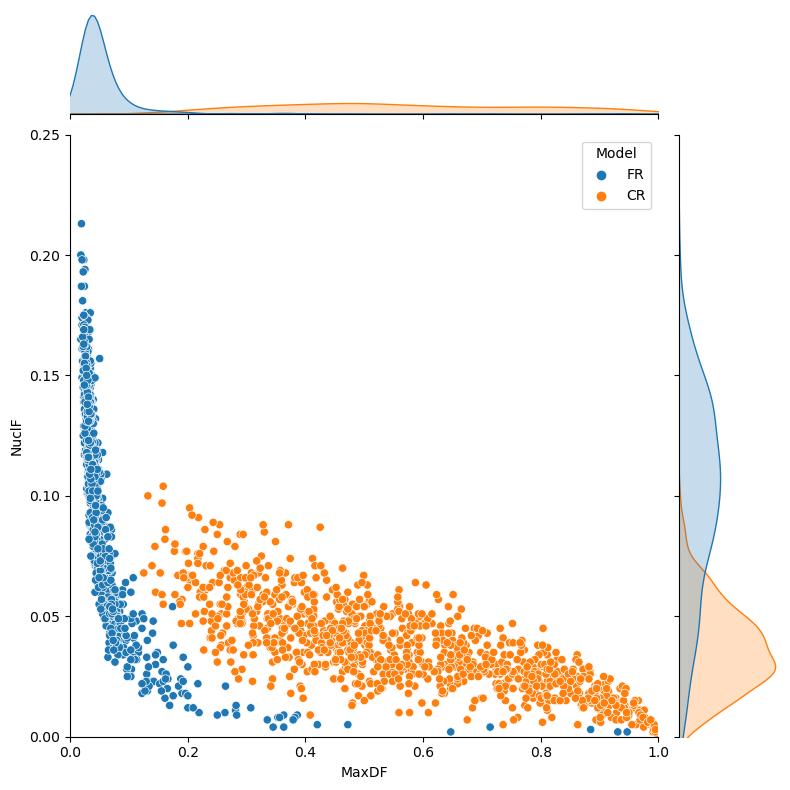

In [164]:
subdf1000 = pd.concat([FR1000, CR1000], axis=0)
sns.jointplot(subdf1000, x='MaxDF', y='NuclF', hue='Model', height=8, xlim=(0, 1), ylim=(0, 0.25));

### N=2000

##### No redirection

In [135]:
%%time

NR2000 = run_func_not('NR', next_rnd_nr, 2000, 250)

  0%|          | 0/250 [00:00<?, ?it/s]

CPU times: user 14min 2s, sys: 3.54 s, total: 14min 6s
Wall time: 14min 6s


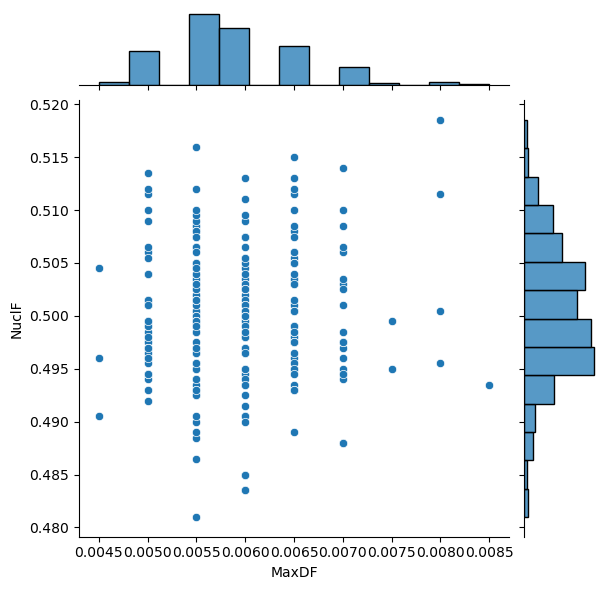

In [136]:
sns.jointplot(NR2000, x='MaxDF', y='NuclF');

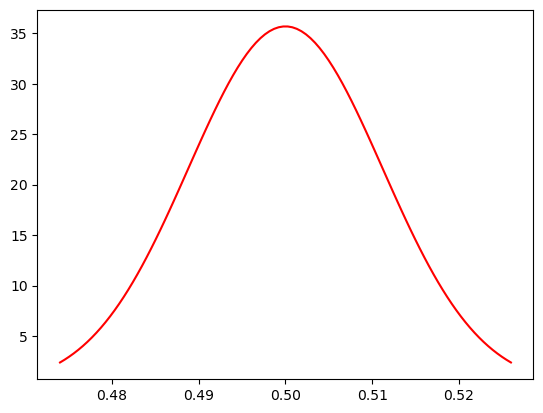

In [15]:
a = 1000
b = 1000
x = np.linspace(beta.ppf(0.01, a, b), beta.ppf(0.99, a, b), 100)
plt.plot(x, beta.pdf(x, a, b), 'r-');

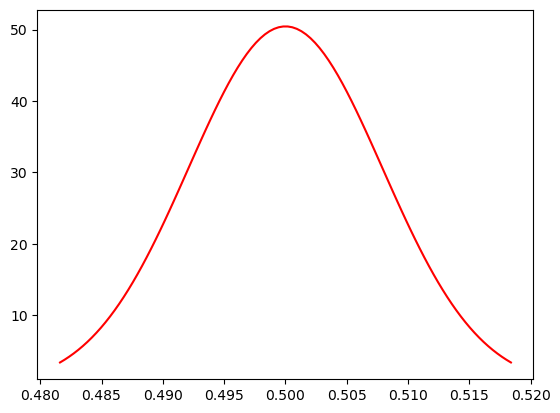

In [17]:
a = 2000
b = 2000
x = np.linspace(beta.ppf(0.01, a, b), beta.ppf(0.99, a, b), 100)
plt.plot(x, beta.pdf(x, a, b), 'r-');

##### Cross redirection

In [137]:
%%time

XR2000 = run_func_not('XR', next_rnd_xr, 1000, 250)

  0%|          | 0/250 [00:00<?, ?it/s]

CPU times: user 13min 54s, sys: 3.31 s, total: 13min 58s
Wall time: 13min 57s


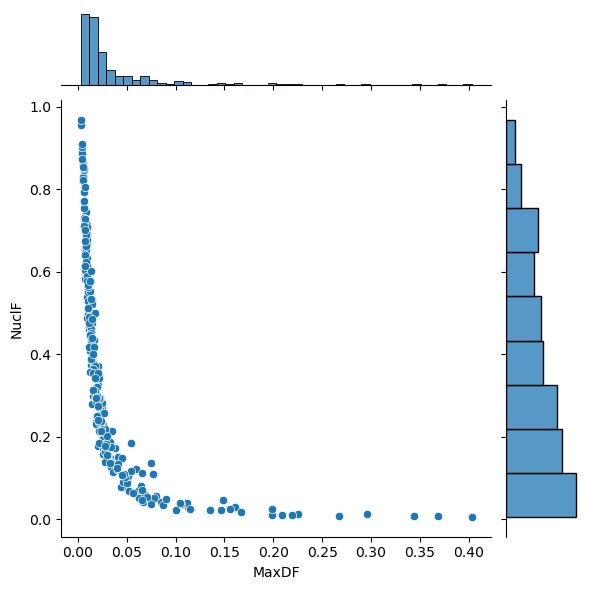

In [138]:
sns.jointplot(XR2000, x='MaxDF', y='NuclF');

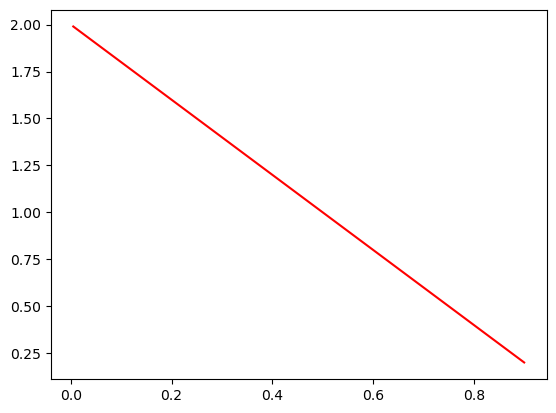

In [18]:
a = 1
b = 2
x = np.linspace(beta.ppf(0.01, a, b), beta.ppf(0.99, a, b), 100)
plt.plot(x, beta.pdf(x, a, b), 'r-');

##### Hub redirection

In [139]:
%%time

HR2000 = run_func_not('HR', next_rnd_hr, 2000, 250)

  0%|          | 0/250 [00:00<?, ?it/s]

CPU times: user 54min 27s, sys: 13.5 s, total: 54min 41s
Wall time: 54min 40s


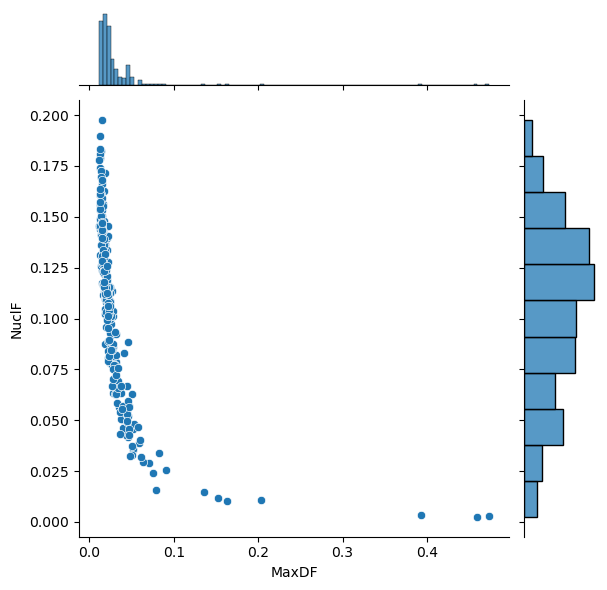

In [140]:
sns.jointplot(HR2000, x='MaxDF', y='NuclF');

##### Fuzzy redirection

In [141]:
%%time

FR2000 = run_func_not('FR', next_rnd_fr, 2000, 250)

  0%|          | 0/250 [00:00<?, ?it/s]

CPU times: user 54min 17s, sys: 13.1 s, total: 54min 30s
Wall time: 54min 29s


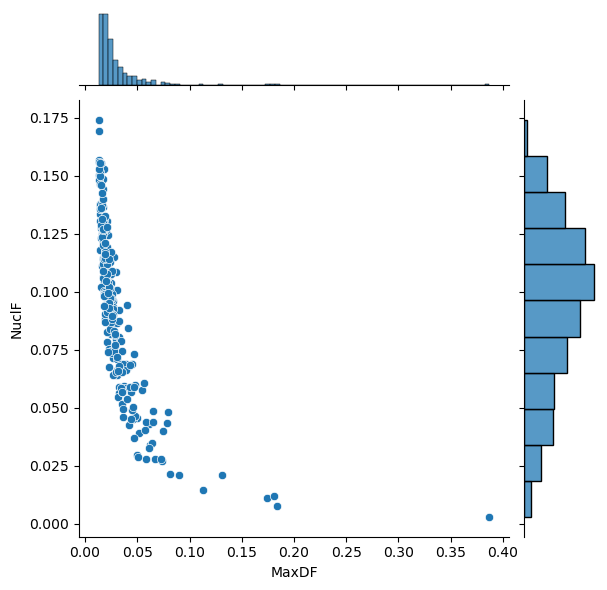

In [142]:
sns.jointplot(FR2000, x='MaxDF', y='NuclF');

##### Complete redirection

In [143]:
%%time

CR2000 = run_func_not('CR', next_rnd_cr, 2000, 250)

  0%|          | 0/250 [00:00<?, ?it/s]

CPU times: user 13min 33s, sys: 3.78 s, total: 13min 37s
Wall time: 13min 36s


In [173]:
%%time

CR2000_2 = run_func_not('CR', next_rnd_cr, 2000, 10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

CPU times: user 9h 16min 9s, sys: 3min 25s, total: 9h 19min 34s
Wall time: 9h 19min 37s


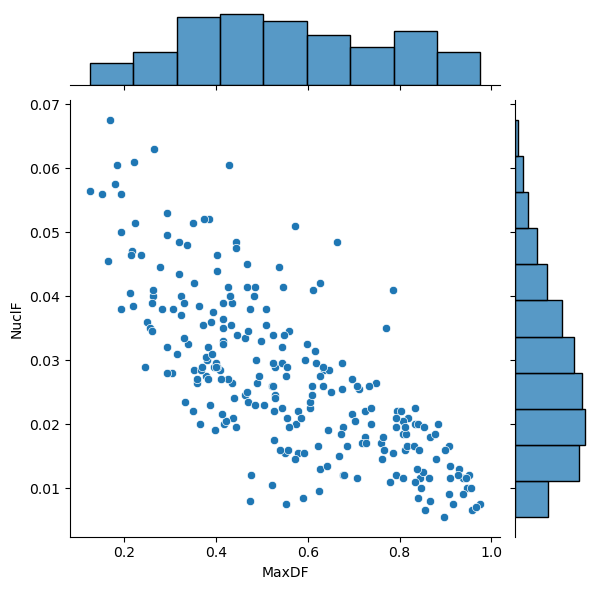

In [144]:
sns.jointplot(CR2000, x='MaxDF', y='NuclF');

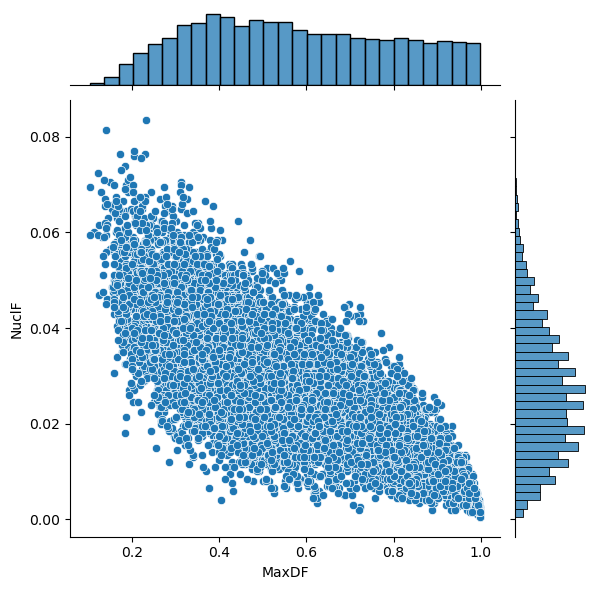

In [174]:
sns.jointplot(CR2000_2, x='MaxDF', y='NuclF');

In [175]:
beta.fit(CR2000_2['NuclF'], floc=0, fscale=1)

(3.127859885851307, 114.78893055325229, 0, 1)

In [199]:
beta.fit(CR2000_2['NuclF'], f0=3, floc=0, fscale=1)

(3, 110.11699573904237, 0, 1)

In [198]:
beta.fit(CR2000_2['NuclF'], f0=3, floc=0, fscale=1, method='MM')

(3, 110.01435069133944, 0, 1)

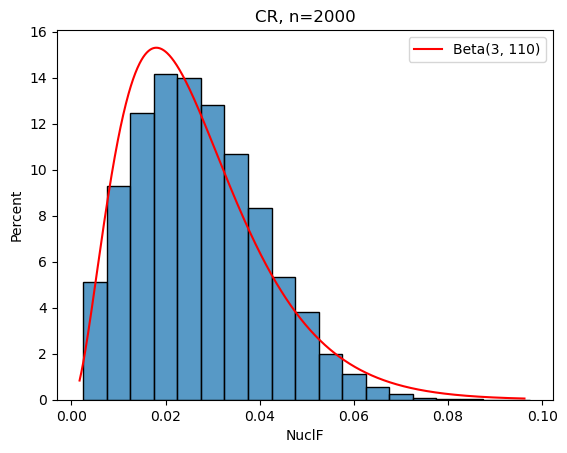

In [214]:
plot_beta_fit(CR2000_2, model='CR, n=2000', a=3, b=110, bin_width=0.005, bin_range=(0, 0.10))

#### Compare

In [145]:
df2000 = pd.concat([NR2000, XR2000, HR2000, FR2000, CR2000], axis=0)

In [157]:
df2000.groupby('Model')[['MaxDF', 'PD1', 'DPD', 'NuclF', 'PH1', 'DPH']].mean()

,MaxDF,PD1,DPD,NuclF,PH1,DPH
Model,,,,,,
CR,0.554236,0.551909,0.000262,0.027566,0.015535,-0.000006
FR,0.031738,0.027609,-0.000033,0.093672,0.071528,-0.000011
HR,0.032826,0.029097,-0.000037,0.103442,0.076817,-0.000013
NR,0.005898,0.003384,-0.000248,0.500326,0.169988,-0.000165
XR,0.038792,0.032966,-0.000317,0.350156,0.118114,-0.000232


In [30]:
(2000.)**(0.566-1)

0.03692776147008702

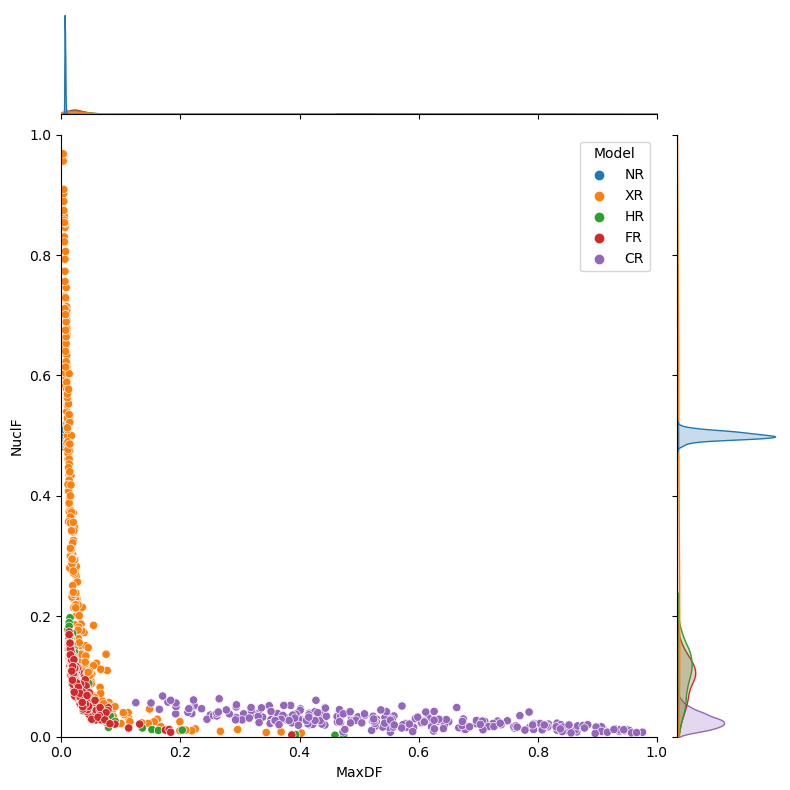

In [149]:
sns.jointplot(df2000, x='MaxDF', y='NuclF', hue='Model', height=8, xlim=(0, 1), ylim=(0, 1));

### N=10000

##### Complete redirection

In [48]:
%%time

CR10000 = run_func_not('CR', next_rnd_cr, 10000, 200)

  0%|          | 0/200 [00:00<?, ?it/s]

CPU times: user 4h 50min 23s, sys: 2min 6s, total: 4h 52min 29s
Wall time: 4h 52min 32s


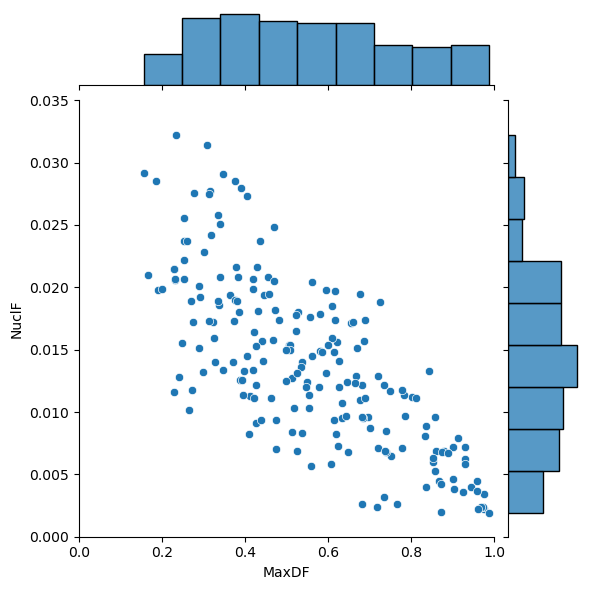

In [58]:
sns.jointplot(CR10000, x='MaxDF', y='NuclF', xlim=(0, 1), ylim=(0, 0.035));

In [59]:
CR10000[['MaxDF', 'PD1', 'DPD', 'NuclF', 'PH1', 'DPH']].describe()

,MaxDF,PD1,DPD,NuclF,PH1,DPH
count,200.000000,200.000000,2.000000e+02,200.000000,200.000000,2.000000e+02
mean,0.553375,0.552765,-6.099973e-08,0.013919,0.007905,-6.013803e-07
std,0.217137,0.217178,2.087085e-08,0.006797,0.003828,2.996266e-07
min,0.155300,0.154638,-1.241947e-07,0.001900,0.001113,-1.496667e-06
25%,0.381825,0.381104,-7.448860e-08,0.008850,0.005098,-8.064745e-07
50%,0.535500,0.535086,-5.913317e-08,0.013300,0.007674,-5.731501e-07
75%,0.705725,0.705375,-4.798063e-08,0.018825,0.010451,-3.839074e-07
max,0.988400,0.988219,-1.549845e-08,0.032200,0.017986,-6.920576e-08
